# Analysing First-Purchase Discount Effectiveness in E-commerce

## Defining the Project Objective
This project evaluates whether first-purchase discounts are associated with improved customer retention and whether the observed customer revenue is sufficient to justify the discount expenditure. The analysis is observational; results should not be interpreted as causal effects.

## Establishing the Business Questions
1. Do customers receiving a first-purchase discount return more often?
2. Does the relationship vary across customer segments and acquisition cohorts?
3. Do discounted customers generate stronger repeat-purchase revenue?
4. What do customer-level economics and hypothetical margin scenarios suggest about the discount strategy?

## Describing the Dataset
The supplied dataset describes a Turkish online retail platform. Monetary values are documented in Turkish lira (TRY). The original source notes a date range from January 2023 to March 2024. The analysis below derives its population counts directly from the CSV.

## Outlining the Analytical Approach
Customer-level aggregation, retention and cohort analysis, hypothesis testing, multiple-comparison correction, logistic regression, revenue analysis and gross-margin sensitivity analysis.

In [1]:
# Imports and data loading
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import mannwhitneyu, fisher_exact
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm

# Load the dataset relative to this notebook's location
df = pd.read_csv("../data/ecommerce_customer_behavior_dataset_v2.csv")
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print(f"Transactions: {len(df):,}")
print(f"Unique customers: {df['Customer_ID'].nunique():,}")
print(f"Unique orders: {df['Order_ID'].nunique():,}")
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")


Transactions: 17,049
Unique customers: 5,000
Unique orders: 17,049
Date range: 2023-01-01 to 2024-03-25


In [2]:
# Core customer-level preparation used throughout the investigation
df = df.sort_values(["Customer_ID", "Date", "Order_ID"]).copy()
df["Has_Discount"] = df["Discount_Amount"].fillna(0).gt(0)
customer_order_counts = df.groupby("Customer_ID")["Order_ID"].nunique()
customer_type = np.where(customer_order_counts.eq(1), "one_time_purchaser", "repeat_purchaser")
df["Customer_Type"] = df["Customer_ID"].map(dict(zip(customer_order_counts.index, customer_type)))
first_purchase = df.groupby("Customer_ID", as_index=False).first()
first_purchase = first_purchase.set_index("Customer_ID", drop=False)
first_purchase["Made_Second_Purchase"] = customer_order_counts.gt(1)

print("Customer population:", first_purchase.shape[0])
print(first_purchase["Has_Discount"].value_counts().rename(index={True: "Discounted", False: "No discount"}))


Customer population: 5000
Has_Discount
No discount    3092
Discounted     1908
Name: count, dtype: int64


## Conducting the Main Business Investigation
The following sections retain the portfolio analysis, beginning with repeat-purchase behaviour and continuing through retention, segmentation, cohorts and customer economics. Preliminary practice exercises have been removed to keep the notebook focused.

In [3]:
df.head(10)

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating,Has_Discount,Customer_Type
0,ORD_000001-1,CUST_00001,2023-05-29,40,Male,Ankara,Books,29.18,1,0.00,29.18,Digital Wallet,Mobile,14,9,True,13,4,False,repeat_purchaser
1,ORD_000001-2,CUST_00001,2023-10-12,40,Male,Ankara,Home & Garden,644.40,1,138.05,506.35,Credit Card,Desktop,14,8,True,6,2,True,repeat_purchaser
2,ORD_000001-3,CUST_00001,2023-12-05,40,Male,Ankara,Sports,332.82,5,0.00,1664.10,Credit Card,Mobile,15,10,True,9,4,False,repeat_purchaser
3,ORD_000002-1,CUST_00002,2023-05-11,33,Male,Istanbul,Food,69.30,5,71.05,275.45,Digital Wallet,Desktop,16,13,True,4,4,True,repeat_purchaser
4,ORD_000002-2,CUST_00002,2023-06-16,33,Male,Istanbul,Beauty,178.15,3,0.00,534.45,Credit Card,Mobile,14,7,True,6,4,False,repeat_purchaser
5,ORD_000003-1,CUST_00003,2023-02-27,42,Male,Konya,Toys,198.28,2,0.00,396.56,Credit Card,Tablet,10,9,False,6,2,False,repeat_purchaser
6,ORD_000003-2,CUST_00003,2024-01-03,42,Male,Konya,Home & Garden,526.85,5,0.00,2634.25,Digital Wallet,Desktop,11,8,True,6,5,False,repeat_purchaser
7,ORD_000004-1,CUST_00004,2024-02-13,53,Male,Izmir,Fashion,96.20,5,97.78,383.22,Credit Card,Desktop,16,15,False,4,5,True,one_time_purchaser
8,ORD_000005-1,CUST_00005,2023-03-16,32,Male,Ankara,Home & Garden,533.67,3,0.00,1601.01,Bank Transfer,Mobile,12,8,False,5,5,False,repeat_purchaser
9,ORD_000005-2,CUST_00005,2023-06-12,32,Male,Ankara,Toys,73.06,4,0.00,292.24,Credit Card,Mobile,13,12,True,7,2,False,repeat_purchaser


In [4]:
df = df.sort_values(["Customer_ID", "Date"])
df.head(10)

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating,Has_Discount,Customer_Type
0,ORD_000001-1,CUST_00001,2023-05-29,40,Male,Ankara,Books,29.18,1,0.00,29.18,Digital Wallet,Mobile,14,9,True,13,4,False,repeat_purchaser
1,ORD_000001-2,CUST_00001,2023-10-12,40,Male,Ankara,Home & Garden,644.40,1,138.05,506.35,Credit Card,Desktop,14,8,True,6,2,True,repeat_purchaser
2,ORD_000001-3,CUST_00001,2023-12-05,40,Male,Ankara,Sports,332.82,5,0.00,1664.10,Credit Card,Mobile,15,10,True,9,4,False,repeat_purchaser
3,ORD_000002-1,CUST_00002,2023-05-11,33,Male,Istanbul,Food,69.30,5,71.05,275.45,Digital Wallet,Desktop,16,13,True,4,4,True,repeat_purchaser
4,ORD_000002-2,CUST_00002,2023-06-16,33,Male,Istanbul,Beauty,178.15,3,0.00,534.45,Credit Card,Mobile,14,7,True,6,4,False,repeat_purchaser
5,ORD_000003-1,CUST_00003,2023-02-27,42,Male,Konya,Toys,198.28,2,0.00,396.56,Credit Card,Tablet,10,9,False,6,2,False,repeat_purchaser
6,ORD_000003-2,CUST_00003,2024-01-03,42,Male,Konya,Home & Garden,526.85,5,0.00,2634.25,Digital Wallet,Desktop,11,8,True,6,5,False,repeat_purchaser
7,ORD_000004-1,CUST_00004,2024-02-13,53,Male,Izmir,Fashion,96.20,5,97.78,383.22,Credit Card,Desktop,16,15,False,4,5,True,one_time_purchaser
8,ORD_000005-1,CUST_00005,2023-03-16,32,Male,Ankara,Home & Garden,533.67,3,0.00,1601.01,Bank Transfer,Mobile,12,8,False,5,5,False,repeat_purchaser
9,ORD_000005-2,CUST_00005,2023-06-12,32,Male,Ankara,Toys,73.06,4,0.00,292.24,Credit Card,Mobile,13,12,True,7,2,False,repeat_purchaser


In [5]:
df[df["Customer_ID"] == "CUST_00002"][["Customer_ID", "Order_ID", "Date"]]

,Customer_ID,Order_ID,Date
3,CUST_00002,ORD_000002-1,2023-05-11
4,CUST_00002,ORD_000002-2,2023-06-16


In [6]:
first_purchase = df.groupby("Customer_ID").first()
len(first_purchase)

5000

In [7]:
first_purchase["Made_Second_Purchase"] = (
    customer_order_counts > 1
)

In [8]:
first_purchase[[
    "Has_Discount",
    "Made_Second_Purchase"
]].head(10)

,Has_Discount,Made_Second_Purchase
Customer_ID,,
CUST_00001,False,True
CUST_00002,True,True
CUST_00003,False,True
CUST_00004,True,False
CUST_00005,False,True
CUST_00006,False,True
CUST_00007,True,False
CUST_00008,True,True
CUST_00009,False,False


In [9]:
first_purchase["Made_Second_Purchase"] = customer_order_counts > 1

In [10]:
print(first_purchase.columns.tolist())

['Order_ID', 'Date', 'Age', 'Gender', 'City', 'Product_Category', 'Unit_Price', 'Quantity', 'Discount_Amount', 'Total_Amount', 'Payment_Method', 'Device_Type', 'Session_Duration_Minutes', 'Pages_Viewed', 'Is_Returning_Customer', 'Delivery_Time_Days', 'Customer_Rating', 'Has_Discount', 'Customer_Type', 'Made_Second_Purchase']


In [11]:
first_purchase.groupby("Has_Discount")["Made_Second_Purchase"].mean()

Has_Discount
False    0.815006
True     0.832285
Name: Made_Second_Purchase, dtype: float64

In [12]:
return_rates = first_purchase.groupby("Has_Discount")["Made_Second_Purchase"].mean()

difference = return_rates[True] - return_rates[False]

print("Difference in return rate:", difference)


Difference in return rate: 0.017278646998679204


In [13]:
group_counts = first_purchase["Has_Discount"].value_counts()
print(group_counts)

Has_Discount
False    3092
True     1908
Name: count, dtype: int64


In [14]:
return_summary = first_purchase.groupby("Has_Discount")["Made_Second_Purchase"].agg(["count", "mean", "sum"])
print(return_summary)

              count      mean   sum
Has_Discount                       
False          3092  0.815006  2520
True           1908  0.832285  1588


In [15]:
from statsmodels.stats.proportion import proportions_ztest
successes = [1588, 2520]
samples = [1908, 3092]

z_stat, p_value = proportions_ztest(successes, samples)

print("Z-statistic:", z_stat)
print("P-value:", p_value)


Z-statistic: 1.5502652687115084
P-value: 0.12107785982643682


### Estimating the 95% Confidence Interval

In [16]:
discounted_success = 1588
discounted_total = 1908

no_discount_success = 2520
no_discount_total = 3092


p_discount = discounted_success / discounted_total
p_no_discount = no_discount_success / no_discount_total

print("Discount:", p_discount)
print("No discount:", p_no_discount)

Discount: 0.8322851153039832
No discount: 0.815006468305304


In [17]:
difference = p_discount - p_no_discount

print("Difference:", difference)

Difference: 0.017278646998679204


In [18]:
se = np.sqrt(
    (p_discount * (1 - p_discount) / discounted_total) + 
    (p_no_discount * (1 - p_no_discount) / no_discount_total)
)
print("Standard error:", se)

Standard error: 0.011041748737529455


In [19]:
lower = difference - 1.96 * se
upper = difference + 1.96 * se

print("Lower:", lower)
print("Upper:", upper)

Lower: -0.004363180526878528
Upper: 0.038920474524236935


Metric	Result
No-discount return rate	81.50%
Discount return rate	83.23%
Observed difference	+1.73 pp
95% CI	−0.44 pp to +3.89 pp
p-value	0.1211
Conclusion	Not statistically significant

Customers receiving a first-purchase discount had a 1.73 percentage-point higher second-purchase rate (83.23% vs. 81.50%), but the difference was not statistically significant (p = 0.121). The 95% confidence interval ranged from −0.44 to +3.89 percentage points, meaning the data does not provide sufficient evidence that first-purchase discounts increase repeat purchasing.

# Assessing the Business Impact

In [20]:
baseline_rate = 0.815006
discount_rate = 0.832285

customers = 1000

expected_without_discount = customers * baseline_rate
expected_with_discount = customers * discount_rate

additional_customers = expected_with_discount - expected_without_discount


print("Expected returning customers without discount:", expected_without_discount)
print("Expected returning customers with discount:", expected_with_discount)
print("Additional returning customers:", additional_customers)

Expected returning customers without discount: 815.006
Expected returning customers with discount: 832.2850000000001
Additional returning customers: 17.27900000000011


For every 1,000 customers receiving a first-purchase discount, we observed about 17 additional customers making a second purchase compared with the no-discount group.

The observed data corresponds to approximately 17 additional repeat customers per 1,000 discounted customers. However, because the difference was not statistically significant, we cannot confidently attribute these additional purchases to the discount.

In [21]:
lower_effect = -0.0044
upper_effect = 0.0389

print("Lower:", 1000 * lower_effect)
print("Upper:", 1000 * upper_effect)

Lower: -4.4
Upper: 38.9


# **Analysing Day-90 Retention**

In [22]:
print("Minimum date:", df["Date"].min())
print("Maxmimum date:", df["Date"].max())

Minimum date: 2023-01-01 00:00:00
Maxmimum date: 2024-03-25 00:00:00


In [23]:
cutoff_date = df["Date"].max() - pd.Timedelta(days = 90)

print("90-day cutoff:", cutoff_date)

90-day cutoff: 2023-12-26 00:00:00


In [24]:
eligible_customers = first_purchase[ first_purchase["Date"] <= cutoff_date].copy()

print("Eligible Customers:", len(eligible_customers))

Eligible Customers: 4759


In [25]:
cohort = eligible_customers[["Date", "Has_Discount"]].copy()

cohort = cohort.rename(columns = {"Date": "First_Purchase_Date"})

cohort.head()

,First_Purchase_Date,Has_Discount
Customer_ID,,
CUST_00001,2023-05-29,False
CUST_00002,2023-05-11,True
CUST_00003,2023-02-27,False
CUST_00005,2023-03-16,False
CUST_00006,2023-07-24,False


In [26]:
df_retention = df.merge(cohort, left_on = "Customer_ID", right_index = True, how = "inner")

df_retention.head()

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,...,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating,Has_Discount_x,Customer_Type,First_Purchase_Date,Has_Discount_y
0,ORD_000001-1,CUST_00001,2023-05-29,40,Male,Ankara,Books,29.18,1,0.00,...,Mobile,14,9,True,13,4,False,repeat_purchaser,2023-05-29,False
1,ORD_000001-2,CUST_00001,2023-10-12,40,Male,Ankara,Home & Garden,644.40,1,138.05,...,Desktop,14,8,True,6,2,True,repeat_purchaser,2023-05-29,False
2,ORD_000001-3,CUST_00001,2023-12-05,40,Male,Ankara,Sports,332.82,5,0.00,...,Mobile,15,10,True,9,4,False,repeat_purchaser,2023-05-29,False
3,ORD_000002-1,CUST_00002,2023-05-11,33,Male,Istanbul,Food,69.30,5,71.05,...,Desktop,16,13,True,4,4,True,repeat_purchaser,2023-05-11,True
4,ORD_000002-2,CUST_00002,2023-06-16,33,Male,Istanbul,Beauty,178.15,3,0.00,...,Mobile,14,7,True,6,4,False,repeat_purchaser,2023-05-11,True


In [27]:
df_retention["Days_Since_First"] = (
    df_retention["Date"] - df_retention["First_Purchase_Date"]).dt.days

df_retention[["Customer_ID", "Date", "First_Purchase_Date", "Days_Since_First"]].head(10)   

,Customer_ID,Date,First_Purchase_Date,Days_Since_First
0,CUST_00001,2023-05-29,2023-05-29,0
1,CUST_00001,2023-10-12,2023-05-29,136
2,CUST_00001,2023-12-05,2023-05-29,190
3,CUST_00002,2023-05-11,2023-05-11,0
4,CUST_00002,2023-06-16,2023-05-11,36
5,CUST_00003,2023-02-27,2023-02-27,0
6,CUST_00003,2024-01-03,2023-02-27,310
8,CUST_00005,2023-03-16,2023-03-16,0
9,CUST_00005,2023-06-12,2023-03-16,88
10,CUST_00005,2023-06-21,2023-03-16,97


In [28]:
day_90_retention = (
    df_retention[
        df_retention["Days_Since_First"] >= 90
    ]
    .groupby("Customer_ID")
    .size()
    .gt(0)
)

In [29]:
# day_90_retention

In [30]:
eligible_customers["Day_90_Retained"] = (
    eligible_customers.index
    .map(day_90_retention)
    .fillna(False)
)

In [31]:
eligible_customers[
    ["Has_Discount", "Day_90_Retained"]
].head(10)

,Has_Discount,Day_90_Retained
Customer_ID,,
CUST_00001,False,True
CUST_00002,True,False
CUST_00003,False,True
CUST_00005,False,True
CUST_00006,False,False
CUST_00008,True,False
CUST_00010,False,True
CUST_00011,False,True
CUST_00013,True,True


In [32]:
retention_summary = (eligible_customers.groupby("Has_Discount")["Day_90_Retained"].agg(["count", "mean", "sum"]))
print(retention_summary)

              count      mean   sum
Has_Discount                       
False          2949  0.721601  2128
True           1810  0.744751  1348


In [33]:
retention_rates = (
    eligible_customers
    .groupby("Has_Discount")["Day_90_Retained"]
    .mean()
)

difference = retention_rates[True] - retention_rates[False]

print("Day-90 retention difference:", difference)
print("Percentage-point difference:", difference * 100)

Day-90 retention difference: 0.023150838658670625
Percentage-point difference: 2.3150838658670625


Customers who received a discount on their first purchase had a 2.32 percentage-point higher Day-90 retention rate than customers who did not receive a discount.

Or, per 1,000 customers:

No discount → ~722 retained

Discount → ~745 retained

Difference → ~23 additional retained customers per 1,000

### Conducting the Statistical Test

In [34]:
from statsmodels.stats.proportion import proportions_ztest

successes = [
    1348, # discount group
    2128 # no discount group
]

samples = [
    1810, # discount group
    2949 # no discount group

]

z_stat, p_value = proportions_ztest(successes, samples)

print("Z-statistic:", z_stat)
print("P-value:", p_value)

Z-statistic: 1.7472218105726993
P-value: 0.08059886982495698


We do not have strong enough statistical evidence to conclude that receiving a first-purchase discount increases Day-90 retention.

### Estimating the Confidence Interval

In [35]:
from statsmodels.stats.proportion import confint_proportions_2indep

ci_low, ci_high = confint_proportions_2indep(
    1348, 1810,
    2128, 2949,
    method = "wald"
)

print("95% CI:", ci_low, ci_high)
print("95% CI percentage points:", ci_low * 100, ci_high * 100)

95% CI: -0.0026395108906572713 0.04894118820799852
95% CI percentage points: -0.2639510890657271 4.894118820799852


Observed result says:

Customers who received a discount had a 2.32 percentage-point higher Day-90 retention rate.

But the confidence interval tells us the plausible range for the true difference:

-0.26 pp to +4.89 pp

So the true effect could potentially be:

-0.26 pp → discounts slightly reduce retention

0 pp → essentially no effect

+2.32 pp → our observed difference

+4.89 pp → discounts have a fairly meaningful positive effect

### Interpreting the Business Findings
Customers receiving a first-purchase discount showed 74.48% Day-90 retention compared with 72.16% among customers without a discount, a 2.32 percentage-point difference. However, this difference was not statistically significant (p = 0.081, 95% CI: -0.26 to +4.89 pp). Therefore, while the observed data suggests a potential positive relationship between first-purchase discounts and long-term retention, the evidence is insufficient to conclude that discounts causally improve retention

## **Evaluating Whether the Discount Cost Was Justified by Retention**

In [36]:
discount_cost = (
    first_purchase.groupby("Has_Discount")["Discount_Amount"].agg(["count", "mean", "sum"])
)

print(discount_cost)

              count       mean        sum
Has_Discount                             
False          3092    0.00000       0.00
True           1908  181.77293  346822.75


Discounted customers: 1,908

Non-discounted customers: 3,092

Discount cost: ₺346,822.75

Day-90 retention:
  No discount: 72.16%
  Discount: 74.48%
Observed retention lift: 2.315 percentage points

But the statistical test gave p = 0.0806, so we cannot confidently attribute that lift to the discount.

In [37]:
# Estimating additional retained customers
discounted_customers = 1810
retention_lift = 0.023150838568670625

additional_retained = discounted_customers * retention_lift

print("Estimated additional retained customers:", additional_retained)


Estimated additional retained customers: 41.90301780929383


The discount group had approximately 42 more day-90 retained customers than we would expect if they had retained at the non-discount group's rate.

In [38]:
# Calculating cost per additional retained customer

total_discount_cost = 346822.75
cost_per_additional_retained = ( total_discount_cost / additional_retained)

print("Cost per additional retained customer:", cost_per_additional_retained)

Cost per additional retained customer: 8276.796472713162


The discounted group showed a 2.32 percentage-point higher day-90 retention rate, equivalent to approximately 42 additional retained customers among the 1,810 discounted customers. However, the program cost ₺346,823 in discounts, resulting in an estimated discount cost of approximately ₺8,277 per additional retained customer

# **Evaluating Customer Economics and Break-Even Requirements**

moving from "Do discount increase retention" to "Even if they do, is the extra retention valuable enough to justify what we're spending?"

In [39]:
# Calculate the value of a retained customer
repeat_revenue = (
    df_retention[df_retention["Days_Since_First"] > 0].groupby("Customer_ID")["Total_Amount"].sum()

)

print("Average repeat revenue per returning customers:", repeat_revenue.mean())

print("Median repeat revenue per returning customers:", repeat_revenue.median())


Average repeat revenue per returning customers: 3796.8811805384044
Median repeat revenue per returning customers: 1952.82


Total discount cost: ₺346,822.75

Discounted customers: 1,810

Observed Day-90 retention lift: 2.315 percentage points

Average repeat revenue per returning customer: ₺3,796.88

Median repeat revenue: ₺1,952.82

In [40]:
# How much additional retention would be needed for the discounts to pay for themselves

# Calculating the break-even number of customers
total_discount_cost = 346822.75
avg_customer_value = repeat_revenue.mean()

break_even_customers = total_discount_cost / avg_customer_value

print("Break-even number of additional customers:", break_even_customers)


Break-even number of additional customers: 91.34411468488986


In [41]:
# converting it into a required retention lift
discounted_customers = 1810

retention_lift = break_even_customers / discounted_customers

print("Required retention lift:", retention_lift)
print("Required retention lift (percentage points):", retention_lift * 100)

Required retention lift: 0.05046636170435904
Required retention lift (percentage points): 5.046636170435904


5.05 percentage points

So the business would need the discount to increase Day-90 retention by roughly 5.05 percentage points for the campaign to break even, assuming the average repeat revenue represents the value of an additional retained customer.

But what we actually observe?

2.315 percentage points.

In [42]:
# Comparing observed vs required

observed_lift = difference

print("Observed retention lift:", observed_lift * 100, "percentage points")
print("Required retention lift:", retention_lift * 100, "percentage points")

Observed retention lift: 2.3150838658670625 percentage points
Required retention lift: 5.046636170435904 percentage points


Customers receiving first-purchase discounts showed a 2.32 percentage-point higher Day-90 retention rate, but this difference was not statistically significant (p = 0.084). Furthermore, the observed retention lift falls substantially below the estimated 5.05 percentage-point lift required to recover the discount cost through average repeat revenue. Therefore, based on this analysis, the discount strategy does not currently appear economically justified

### **Calculating the break-even using the median repeat revenue as a more conservative scenario**

In [43]:
median_repeat_revenue = 1952.82

break_even_customers = ( discount_cost.loc[True, "sum"] / median_repeat_revenue)

print("Break-even additional retained customers:", break_even_customers)

Break-even additional retained customers: 177.60098216937558


about 178 additional retained customers

In [44]:
# converting into a required retention lift

discounted_customers = group_counts[True]

break_even_lift = (break_even_customers / discounted_customers)

print("Break-even retention lift:", break_even_lift)
print("Break-even retention lift (percentage points):", break_even_lift * 100)

Break-even retention lift: 0.093082275770113
Break-even retention lift (percentage points): 9.3082275770113


At the median repeat-revenue value of ₺1,952.82, the discount program would need to generate approximately a 9.31 percentage-point retention lift among discounted customers to break even.

In [45]:
observed_lift = difference

break_even_ratio = observed_lift / break_even_lift

print("Observed retention lift:", observed_lift * 100, "percentage points")
print("Break-even retention lift:", break_even_lift * 100, "percentage points")
print("Observed lift as % of break-even:", break_even_ratio * 100, "%")

Observed retention lift: 2.3150838658670625 percentage points
Break-even retention lift: 9.3082275770113 percentage points
Observed lift as % of break-even: 24.871371555038767 %


Discounted customers showed a 2.32 percentage-point higher Day-90 retention rate, but this difference was not statistically significant. More importantly, the observed lift falls well below the estimated 9.31 percentage-point retention improvement required to recover discount costs under the conservative median-revenue scenario. Based on the available data, the discount strategy does not currently appear economically justified

### **Evaluating Contribution Margin**

In [46]:
margin_scenarios = [0.20, 0.30, 0.40, 0.50]

for margin in margin_scenarios:
    contribution_per_customer = median_repeat_revenue * margin

    print(
        f"{margin:.0%} margin:",
        f"₺{contribution_per_customer:.2f} contribution per customer"


    )


20% margin: ₺390.56 contribution per customer
30% margin: ₺585.85 contribution per customer
40% margin: ₺781.13 contribution per customer
50% margin: ₺976.41 contribution per customer


This answers:

"If a returning customer generates ₺1,952.82 in repeat revenue, how much economic value does that customer actually contribute?"

For example, at a 30% margin:

1952.82×0.30=₺585.85

In [47]:
# Calculating how many additional customers the discount actually appears to generate
observed_additional_customers = (
    discounted_customers * difference
)

print("Observed additional retained customers:",
      observed_additional_customers)

Observed additional retained customers: 44.17180016074355


In [48]:
# Comparing contribution against the actual discount cost

discount_cost_total = discount_cost.loc[True, "sum"]

for margin in margin_scenarios:
    
    contribution_per_customer = median_repeat_revenue * margin
    
    total_contribution = (
        observed_additional_customers
        * contribution_per_customer
    )
    
    net_impact = total_contribution - discount_cost_total
    
    print(f"\nMargin: {margin:.0%}")
    print("Total contribution:", total_contribution)
    print("Net impact:", net_impact)


Margin: 20%
Total contribution: 17251.914957980644
Net impact: -329570.8350420194

Margin: 30%
Total contribution: 25877.872436970967
Net impact: -320944.87756302906

Margin: 40%
Total contribution: 34503.82991596129
Net impact: -312318.9200840387

Margin: 50%
Total contribution: 43129.78739495161
Net impact: -303692.9626050484


## **Estimating the Retention Lift Required for Economic Viability**

In [49]:
margin = 0.30

break_even_lift = (discount_cost_total / (discounted_customers * median_repeat_revenue * margin))

print("Break-even retention lift:", break_even_lift)

print("Break-even retention lift (percentage points):", break_even_lift * 100)

Break-even retention lift: 0.3102742525670433
Break-even retention lift (percentage points): 31.027425256704326


Under the observed retention difference and a 30% contribution-margin assumption, the discount program does not appear economically viable. The observed 2.32 percentage-point retention difference is substantially below the estimated 31.03 percentage-point lift required to break even.

Because this is observational analysis rather than a randomized experiment, the estimated incremental retention should not be interpreted as a causal effect of discounts.

In [50]:
# break-even lift for all four margins, rather than only 30%

for margin in margin_scenarios:
    
    break_even_lift = (
        discount_cost_total
        / (discounted_customers * median_repeat_revenue * margin)
    )
    
    print(
        f"{margin:.0%} margin:",
        f"{break_even_lift * 100:.2f} percentage points"
    )

20% margin: 46.54 percentage points
30% margin: 31.03 percentage points
40% margin: 23.27 percentage points
50% margin: 18.62 percentage points


Recommendation: The analysis does not support continuing the first-purchase discount program in its current form. Discounted customers showed slightly higher Day-90 retention (+2.32 percentage points), but the difference was not statistically significant (p = 0.081). More importantly, the estimated retention lift is far below the level required to recover the discount cost. Under a 30% contribution-margin assumption, the program would require approximately a 31 percentage-point retention lift to break even, compared with the observed 2.32 percentage-point lift.

Because this is observational data, these results should not be interpreted as proof that discounts have no causal effect. However, the current evidence suggests that the program is unlikely to be economically attractive at its current cost and targeting strategy.

In [51]:
final_economics = pd.DataFrame({
    "Metric": [
        "Discount customers",
        "Non-discount customers",
        "Day-90 retention — Discount",
        "Day-90 retention — No Discount",
        "Observed retention lift",
        "95% CI for retention lift",
        "P-value",
        "Total discount cost",
        "Observed additional retained customers",
        "Cost per additional retained customer",
        "Median repeat revenue",
        "20% margin break-even lift",
        "30% margin break-even lift",
        "40% margin break-even lift",
        "50% margin break-even lift"
    ],

    "Result": [
        discounted_customers,
        group_counts[False],
        f"{retention_rates[True] * 100:.2f}%",
        f"{retention_rates[False] * 100:.2f}%",
        f"{difference * 100:.2f} percentage points",
        f"{ci_low * 100:.2f} to {ci_high * 100:.2f} percentage points",
        f"{p_value:.4f}",
        f"₺{discount_cost_total:,.2f}",
        f"{observed_additional_customers:.2f}",
        f"₺{discount_cost_total / observed_additional_customers:,.2f}",
        f"₺{median_repeat_revenue:,.2f}",
        "46.54 percentage points",
        "31.03 percentage points",
        "23.27 percentage points",
        "18.62 percentage points"
    ]
})

final_economics

,Metric,Result
0,Discount customers,1908
1,Non-discount customers,3092
2,Day-90 retention — Discount,74.48%
3,Day-90 retention — No Discount,72.16%
4,Observed retention lift,2.32 percentage points
5,95% CI for retention lift,-0.26 to 4.89 percentage points
6,P-value,0.0806
7,Total discount cost,"₺346,822.75"
8,Observed additional retained customers,44.17
9,Cost per additional retained customer,"₺7,851.68"


The analysis found that customers who received first-purchase discounts had slightly higher observed second-purchase and Day-90 retention rates than customers who did not receive discounts. However, neither difference was statistically significant at the 5% level.

The economic analysis suggests that the observed retention difference is insufficient to justify the discount programme under the contribution-margin assumptions tested.

Rather than immediately discontinuing all discounts, the business should investigate whether certain customer segments exhibit different retention patterns. This could help determine whether a more targeted discount strategy deserves further investigation.

Because this analysis is observational, the findings should be interpreted as associations rather than causal effects.

# **Segmenting Customers**

In [52]:
print("Customer Type:")
print(first_purchase["Customer_Type"].value_counts(dropna=False))

print("\nGender:")
print(first_purchase["Gender"].value_counts(dropna=False))

print("\nDevice Type:")
print(first_purchase["Device_Type"].value_counts(dropna=False))

print("\nFirst-Purchase Product Category:")
print(first_purchase["Product_Category"].value_counts(dropna=False))

print("\nAge Summary:")
print(first_purchase["Age"].describe())

Customer Type:
Customer_Type
repeat_purchaser      4108
one_time_purchaser     892
Name: count, dtype: int64

Gender:
Gender
Female    2492
Male      2435
Other       73
Name: count, dtype: int64

Device Type:
Device_Type
Mobile     2847
Desktop    1678
Tablet      475
Name: count, dtype: int64

First-Purchase Product Category:
Product_Category
Sports           675
Books            674
Beauty           664
Toys             620
Electronics      612
Fashion          604
Home & Garden    589
Food             562
Name: count, dtype: int64

Age Summary:
count    5000.000000
mean       35.032600
std        11.080546
min        18.000000
25%        27.000000
50%        35.000000
75%        42.000000
max        75.000000
Name: Age, dtype: float64


In [53]:
print(
    eligible_customers["Has_Discount"]
    .value_counts(dropna=False)
)

Has_Discount
False    2949
True     1810
Name: count, dtype: int64


### Comparing Retention by Device and Discount Status

In [54]:
device_retention = (eligible_customers.groupby(["Device_Type", "Has_Discount"])["Day_90_Retained"]
.agg(["count", "mean", "sum"]).reset_index())

device_retention["Retention_Rate"] = (device_retention["mean"] * 100)

device_retention = device_retention.rename(columns = {"count": "Eligible_Customers", "sum": "Retained_Customers"})

device_retention

,Device_Type,Has_Discount,Eligible_Customers,mean,Retained_Customers,Retention_Rate
0,Desktop,False,988,0.722672,714,72.267206
1,Desktop,True,609,0.750411,457,75.041051
2,Mobile,False,1669,0.727981,1215,72.798083
3,Mobile,True,1041,0.754083,785,75.408261
4,Tablet,False,292,0.681507,199,68.150685
5,Tablet,True,160,0.662500,106,66.250000


### Estimating the Retention Lift for Each Device

In [55]:
device_pivot = device_retention.pivot(index="Device_Type", columns="Has_Discount", values="Retention_Rate")

device_pivot.columns = ["No_Discount", "Discount"]

device_pivot["Retention_Lift_pp"] = (device_pivot["Discount"] - device_pivot["No_Discount"])

device_pivot

,No_Discount,Discount,Retention_Lift_pp
Device_Type,,,
Desktop,72.267206,75.041051,2.773844
Mobile,72.798083,75.408261,2.610179
Tablet,68.150685,66.250000,-1.900685


In [56]:
from statsmodels.stats.proportion import proportions_ztest

for device in eligible_customers["Device_Type"].unique():

    device_data = eligible_customers[
        eligible_customers["Device_Type"] == device
    ]

    # Group-level retained customer counts
    retained = (
        device_data.groupby("Has_Discount")["Day_90_Retained"]
        .sum()
    )

    # Group-level sample sizes
    sample_sizes = (
        device_data.groupby("Has_Discount")["Day_90_Retained"]
        .count()
    )

    # Order: discount first, no discount second
    successes = [
        retained.get(True, 0),
        retained.get(False, 0)
    ]

    samples = [
        sample_sizes.get(True, 0),
        sample_sizes.get(False, 0)
    ]

    z_stat, p_value = proportions_ztest(
        successes,
        samples
    )

    print(f"\nDevice: {device}")
    print("Discounted retention:", successes[0] / samples[0] * 100)
    print("Non-discounted retention:", successes[1] / samples[1] * 100)
    print("Z-statistic:", z_stat)
    print("P-value:", p_value)


Device: Mobile
Discounted retention: 75.40826128722382
Non-discounted retention: 72.79808268424206
Z-statistic: 1.5030181725554979
P-value: 0.13283435788230433

Device: Desktop
Discounted retention: 75.04105090311987
Non-discounted retention: 72.2672064777328
Z-statistic: 1.2174143849117185
P-value: 0.22344659267752864

Device: Tablet
Discounted retention: 66.25
Non-discounted retention: 68.15068493150685
Z-statistic: -0.41249831521795793
P-value: 0.6799742153230218


Device Type Segmentation — Findings and Interpretation

Day-90 retention was compared between customers who received a first-purchase discount and those who did not, across mobile, desktop, and tablet users.

Mobile customers showed a 2.61 percentage-point higher retention rate among discounted customers (75.41% vs. 72.80%), while desktop customers showed a 2.77 percentage-point higher rate (75.04% vs. 72.27%). Tablet customers showed the opposite pattern, with discounted customers having a 1.90 percentage-point lower retention rate (66.25% vs. 68.15%).

Two-proportion z-tests found that none of these differences was statistically significant at the 5% level (mobile: p = 0.133; desktop: p = 0.223; tablet: p = 0.680). Therefore, we do not have sufficient statistical evidence that discounts are associated with different Day-90 retention rates within any of the three device groups.

Business implication: Device type has not provided convincing evidence that the discount strategy should be targeted differently across devices. The observed differences are worth documenting, but they do not establish that discounts improve retention for mobile or desktop customers or reduce it for tablet customers. Further segmentation analysis will investigate whether other customer characteristics reveal more meaningful patterns.

### Comparing Day-90 Retention by Gender and Discount Status

In [57]:
gender_retention = (eligible_customers.groupby(["Gender", "Has_Discount"])["Day_90_Retained"].agg(["count", "sum", "mean"]).reset_index())

gender_retention["Retention_Rate"] = (gender_retention["mean"] * 100)

gender_retention = gender_retention.rename(columns={"count": "Eligible_Customers", "sum": "Retained_Customers"})

gender_retention

,Gender,Has_Discount,Eligible_Customers,Retained_Customers,mean,Retention_Rate
0,Female,False,1469,1067,0.726344,72.634445
1,Female,True,902,690,0.764967,76.496674
2,Male,False,1434,1027,0.716179,71.617852
3,Male,True,883,639,0.723669,72.366931
4,Other,False,46,34,0.739130,73.913043
5,Other,True,25,19,0.760000,76.000000


### Estimating the Retention Lift

In [58]:
gender_pivot = gender_retention.pivot(index="Gender", columns="Has_Discount", values="Retention_Rate")

gender_pivot.columns = ["No_Discount", "Discount"]

gender_pivot["Retention_Lift_pp"] = (gender_pivot["Discount"] - gender_pivot["No_Discount"])

gender_pivot

,No_Discount,Discount,Retention_Lift_pp
Gender,,,
Female,72.634445,76.496674,3.862229
Male,71.617852,72.366931,0.749079
Other,73.913043,76.000000,2.086957


In [59]:
from statsmodels.stats.proportion import proportions_ztest

gender_test_results = []

for gender in eligible_customers["Gender"].unique():

    gender_data = eligible_customers[
        eligible_customers["Gender"] == gender
    ]

    retained = (
        gender_data.groupby("Has_Discount")["Day_90_Retained"]
        .sum()
    )

    sample_sizes = (
        gender_data.groupby("Has_Discount")["Day_90_Retained"]
        .count()
    )

    # Discount first, no discount second
    successes = [
        retained.get(True, 0),
        retained.get(False, 0)
    ]

    samples = [
        sample_sizes.get(True, 0),
        sample_sizes.get(False, 0)
    ]

    z_stat, p_value = proportions_ztest(
        successes,
        samples
    )

    gender_test_results.append({
        "Gender": gender,
        "Discount_Customers": samples[0],
        "No_Discount_Customers": samples[1],
        "Z_Statistic": z_stat,
        "P_Value": p_value
    })

gender_test_results = pd.DataFrame(gender_test_results)

gender_test_results

,Gender,Discount_Customers,No_Discount_Customers,Z_Statistic,P_Value
0,Male,883,1434,0.389599,0.696833
1,Female,902,1469,2.084241,0.037138
2,Other,25,46,0.193071,0.846903


In [60]:
from statsmodels.stats.multitest import multipletests

gender_test_results["Adjusted_P_Value"] = multipletests(
    gender_test_results["P_Value"],
    method="holm"
)[1]

gender_test_results["Significant_After_Correction"] = (
    gender_test_results["Adjusted_P_Value"] < 0.05
)

gender_test_results

,Gender,Discount_Customers,No_Discount_Customers,Z_Statistic,P_Value,Adjusted_P_Value,Significant_After_Correction
0,Male,883,1434,0.389599,0.696833,1.000000,False
1,Female,902,1469,2.084241,0.037138,0.111415,False
2,Other,25,46,0.193071,0.846903,1.000000,False


#### Interpreting the Gender-Based Findings

# Comparing Day-90 Retention by Age Group and Discount Status

In [61]:
# Creating age groups

age_bins = [17, 24, 34, 49, float("inf")]

age_labels = ["18-24", "25-34", "35-49", "50+"
]

eligible_customers["Age_Group"] = pd.cut(eligible_customers["Age"], bins=age_bins, labels=age_labels)

# Checking the number of customers in each age group

print(eligible_customers["Age_Group"].value_counts().sort_index())

Age_Group
18-24     946
25-34    1410
35-49    1917
50+       486
Name: count, dtype: int64


In [62]:
# Calculating Day-90 retention by age group and discount status

age_retention = (
    eligible_customers
    .groupby(["Age_Group", "Has_Discount"], observed=True)["Day_90_Retained"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Convert retention rate to percentage
age_retention["Retention_Rate"] = age_retention["mean"] * 100

# Rename columns for clarity
age_retention = age_retention.rename(columns={"count": "Eligible_Customers","sum": "Retained_Customers"})

age_retention

,Age_Group,Has_Discount,Eligible_Customers,Retained_Customers,mean,Retention_Rate
0,18-24,False,578,424,0.733564,73.356401
1,18-24,True,368,269,0.730978,73.097826
2,25-34,False,891,638,0.716049,71.604938
3,25-34,True,519,382,0.736031,73.603083
4,35-49,False,1181,855,0.723963,72.396274
5,35-49,True,736,563,0.764946,76.494565
6,50+,False,299,211,0.705686,70.568562
7,50+,True,187,134,0.716578,71.657754


In [63]:
# Calculate retention lift by age group

age_pivot = age_retention.pivot(index="Age_Group", columns="Has_Discount", values="Retention_Rate")

age_pivot.columns = ["No_Discount", "Discount"]

age_pivot["Retention_Lift_pp"] = (age_pivot["Discount"] - age_pivot["No_Discount"])

age_pivot

,No_Discount,Discount,Retention_Lift_pp
Age_Group,,,
18-24,73.356401,73.097826,-0.258575
25-34,71.604938,73.603083,1.998145
35-49,72.396274,76.494565,4.098291
50+,70.568562,71.657754,1.089192


In [64]:
from statsmodels.stats.proportion import proportions_ztest

age_test_results = []

for age_group in eligible_customers["Age_Group"].dropna().unique():

    age_data = eligible_customers[
        eligible_customers["Age_Group"] == age_group
    ]

    retained = (
        age_data.groupby("Has_Discount")["Day_90_Retained"]
        .sum()
    )

    sample_sizes = (
        age_data.groupby("Has_Discount")["Day_90_Retained"]
        .count()
    )

    # Discount group first, non-discount group second
    successes = [
        retained.get(True, 0),
        retained.get(False, 0)
    ]

    samples = [
        sample_sizes.get(True, 0),
        sample_sizes.get(False, 0)
    ]

    z_stat, p_value = proportions_ztest(
        successes,
        samples
    )

    age_test_results.append({
        "Age_Group": age_group,
        "Discount_Customers": samples[0],
        "No_Discount_Customers": samples[1],
        "Z_Statistic": z_stat,
        "P_Value": p_value
    })

age_test_results = pd.DataFrame(age_test_results)

age_test_results

,Age_Group,Discount_Customers,No_Discount_Customers,Z_Statistic,P_Value
0,35-49,736,1181,1.988792,0.046724
1,25-34,519,891,0.808959,0.418539
2,18-24,368,578,-0.087598,0.930196
3,50+,187,299,0.257430,0.796846


In [65]:
from statsmodels.stats.multitest import multipletests

age_test_results["Adjusted_P_Value"] = multipletests(
    age_test_results["P_Value"],
    method="holm"
)[1]

age_test_results["Significant_After_Correction"] = (
    age_test_results["Adjusted_P_Value"] < 0.05
)

age_test_results

,Age_Group,Discount_Customers,No_Discount_Customers,Z_Statistic,P_Value,Adjusted_P_Value,Significant_After_Correction
0,35-49,736,1181,1.988792,0.046724,0.186897,False
1,25-34,519,891,0.808959,0.418539,1.000000,False
2,18-24,368,578,-0.087598,0.930196,1.000000,False
3,50+,187,299,0.257430,0.796846,1.000000,False


The 35–49 age group initially appeared to have a statistically significant retention difference, but that finding did not survive the Holm correction.

Its adjusted p-value increased from 0.0467 to 0.1869.

The observed retention lift remains approximately 4.10 percentage points. However, we don't have sufficient statistical evidence to declare the difference significant after accounting for multiple comparisons.

The other age groups also show no statistically significant differences.

Business implication

Age segmentation has not provided sufficiently strong statistical evidence to justify targeting first-purchase discounts at a particular age group.

The 35–49 group remains interesting because it has the largest observed retention lift, but we should treat this as a hypothesis for further investigation rather than a proven business opportunity.

# Comparing Day-90 Retention by Product Category and Discount Status

In [66]:
# Inspect first-purchase product category distribution

print(
    first_purchase["Product_Category"]
    .value_counts(dropna=False)
    
)

Product_Category
Sports           675
Books            674
Beauty           664
Toys             620
Electronics      612
Fashion          604
Home & Garden    589
Food             562
Name: count, dtype: int64


In [67]:
# Calculating Day-90 retention by first-purchase product category
# and discount status

category_retention = (eligible_customers.groupby(["Product_Category", "Has_Discount"],observed=True)["Day_90_Retained"].agg(["count", "sum", "mean"]).reset_index())

# Converting retention rates to percentages
category_retention["Retention_Rate"] = (category_retention["mean"] * 100)

# Renaming columns for clarity
category_retention = category_retention.rename(columns={"count": "Eligible_Customers","sum": "Retained_Customers"})

category_retention

,Product_Category,Has_Discount,Eligible_Customers,Retained_Customers,mean,Retention_Rate
0,Beauty,False,387,284,0.733850,73.385013
1,Beauty,True,248,180,0.725806,72.580645
2,Books,False,406,285,0.701970,70.197044
3,Books,True,231,178,0.770563,77.056277
4,Electronics,False,369,276,0.747967,74.796748
5,Electronics,True,222,164,0.738739,73.873874
6,Fashion,False,363,255,0.702479,70.247934
7,Fashion,True,206,145,0.703883,70.388350
8,Food,False,332,238,0.716867,71.686747
9,Food,True,207,150,0.724638,72.463768


In [68]:
# Compare discounted and non-discounted retention rates

category_pivot = category_retention.pivot(
    index="Product_Category",
    columns="Has_Discount",
    values="Retention_Rate"
)

# Give the columns meaningful names
category_pivot.columns = ["No_Discount", "Discount"]

# Calculate retention lift in percentage points
category_pivot["Retention_Lift_pp"] = (
    category_pivot["Discount"]
    - category_pivot["No_Discount"]
)

category_pivot.sort_values(
    "Retention_Lift_pp",
    ascending=False
)

,No_Discount,Discount,Retention_Lift_pp
Product_Category,,,
Books,70.197044,77.056277,6.859233
Sports,71.502591,77.865613,6.363022
Home & Garden,70.809249,74.654378,3.845129
Toys,74.722222,76.106195,1.383972
Food,71.686747,72.463768,0.777021
Fashion,70.247934,70.388350,0.140416
Beauty,73.385013,72.580645,-0.804368
Electronics,74.796748,73.873874,-0.922874


In [69]:
from statsmodels.stats.proportion import proportions_ztest

category_test_results = []

for category in eligible_customers["Product_Category"].dropna().unique():

    category_data = eligible_customers[
        eligible_customers["Product_Category"] == category
    ]

    retained = (
        category_data.groupby("Has_Discount")["Day_90_Retained"]
        .sum()
    )

    sample_sizes = (
        category_data.groupby("Has_Discount")["Day_90_Retained"]
        .count()
    )

    # Discount group first, no-discount group second
    successes = [
        retained.get(True, 0),
        retained.get(False, 0)
    ]

    samples = [
        sample_sizes.get(True, 0),
        sample_sizes.get(False, 0)
    ]

    z_stat, p_value = proportions_ztest(
        successes,
        samples
    )

    category_test_results.append({
        "Product_Category": category,
        "Discount_Customers": samples[0],
        "No_Discount_Customers": samples[1],
        "Z_Statistic": z_stat,
        "P_Value": p_value
    })

category_test_results = pd.DataFrame(category_test_results)

category_test_results

,Product_Category,Discount_Customers,No_Discount_Customers,Z_Statistic,P_Value
0,Books,231,406,1.867881,0.061779
1,Food,207,332,0.195379,0.845097
2,Toys,226,360,0.377901,0.705504
3,Home & Garden,217,346,0.992141,0.321129
4,Beauty,248,387,-0.222929,0.823591
5,Sports,253,386,1.793838,0.072839
6,Fashion,206,363,0.035228,0.971898
7,Electronics,222,369,-0.249121,0.803267


In [70]:
print("Categories in first_purchase:")
print(sorted(first_purchase["Product_Category"].dropna().unique()))

print("\nCategories tested:")
print(sorted(category_test_results["Product_Category"].unique()))

Categories in first_purchase:
['Beauty', 'Books', 'Electronics', 'Fashion', 'Food', 'Home & Garden', 'Sports', 'Toys']

Categories tested:
['Beauty', 'Books', 'Electronics', 'Fashion', 'Food', 'Home & Garden', 'Sports', 'Toys']


In [71]:
from statsmodels.stats.multitest import multipletests

category_test_results["Adjusted_P_Value"] = multipletests(category_test_results["P_Value"],method="holm")[1]

category_test_results["Significant_After_Correction"] = (category_test_results["Adjusted_P_Value"] < 0.05)

category_test_results.sort_values("Adjusted_P_Value")

,Product_Category,Discount_Customers,No_Discount_Customers,Z_Statistic,P_Value,Adjusted_P_Value,Significant_After_Correction
0,Books,231,406,1.867881,0.061779,0.494230,False
5,Sports,253,386,1.793838,0.072839,0.509874,False
2,Toys,226,360,0.377901,0.705504,1.000000,False
1,Food,207,332,0.195379,0.845097,1.000000,False
3,Home & Garden,217,346,0.992141,0.321129,1.000000,False
4,Beauty,248,387,-0.222929,0.823591,1.000000,False
6,Fashion,206,363,0.035228,0.971898,1.000000,False
7,Electronics,222,369,-0.249121,0.803267,1.000000,False


Day-90 retention was compared between discounted and non-discounted customers across eight first-purchase product categories. Two-proportion z-tests were conducted within each category, followed by Holm correction to account for multiple comparisons.

Books recorded the largest observed retention lift at 6.86 percentage points, followed by Sports at 6.36 percentage points and Home & Garden at 3.85 percentage points. However, none of the eight categories showed a statistically significant difference before or after the Holm correction.

Business implication: The analysis does not provide sufficient statistical evidence to recommend targeting first-purchase discounts by product category. Books and Sports may warrant further investigation because of their larger observed retention differences, but these findings should be treated as hypotheses rather than proven opportunities.

# **Analysing Customer Cohorts**

#### Examining How Retention Evolved Across Acquisition Cohorts
#### Measuring Subsequent-Month Repeat Purchasing Across Cohorts

In [72]:
df.head(10)

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating,Has_Discount,Customer_Type
0,ORD_000001-1,CUST_00001,2023-05-29,40,Male,Ankara,Books,29.18,1,0.00,29.18,Digital Wallet,Mobile,14,9,True,13,4,False,repeat_purchaser
1,ORD_000001-2,CUST_00001,2023-10-12,40,Male,Ankara,Home & Garden,644.40,1,138.05,506.35,Credit Card,Desktop,14,8,True,6,2,True,repeat_purchaser
2,ORD_000001-3,CUST_00001,2023-12-05,40,Male,Ankara,Sports,332.82,5,0.00,1664.10,Credit Card,Mobile,15,10,True,9,4,False,repeat_purchaser
3,ORD_000002-1,CUST_00002,2023-05-11,33,Male,Istanbul,Food,69.30,5,71.05,275.45,Digital Wallet,Desktop,16,13,True,4,4,True,repeat_purchaser
4,ORD_000002-2,CUST_00002,2023-06-16,33,Male,Istanbul,Beauty,178.15,3,0.00,534.45,Credit Card,Mobile,14,7,True,6,4,False,repeat_purchaser
5,ORD_000003-1,CUST_00003,2023-02-27,42,Male,Konya,Toys,198.28,2,0.00,396.56,Credit Card,Tablet,10,9,False,6,2,False,repeat_purchaser
6,ORD_000003-2,CUST_00003,2024-01-03,42,Male,Konya,Home & Garden,526.85,5,0.00,2634.25,Digital Wallet,Desktop,11,8,True,6,5,False,repeat_purchaser
7,ORD_000004-1,CUST_00004,2024-02-13,53,Male,Izmir,Fashion,96.20,5,97.78,383.22,Credit Card,Desktop,16,15,False,4,5,True,one_time_purchaser
8,ORD_000005-1,CUST_00005,2023-03-16,32,Male,Ankara,Home & Garden,533.67,3,0.00,1601.01,Bank Transfer,Mobile,12,8,False,5,5,False,repeat_purchaser
9,ORD_000005-2,CUST_00005,2023-06-12,32,Male,Ankara,Toys,73.06,4,0.00,292.24,Credit Card,Mobile,13,12,True,7,2,False,repeat_purchaser


In [73]:
# Create a customer-level dataset using each customer's earliest purchase

customer_cohorts = (df.groupby("Customer_ID")["Date"].min().reset_index().rename(columns={"Date": "First_Purchase_Date"}))

# Assign each customer to their first-purchase month
customer_cohorts["Cohort_Month"] = (customer_cohorts["First_Purchase_Date"].dt.to_period("M"))

# Inspect the results
customer_cohorts.head(10)

,Customer_ID,First_Purchase_Date,Cohort_Month
0,CUST_00001,2023-05-29,2023-05
1,CUST_00002,2023-05-11,2023-05
2,CUST_00003,2023-02-27,2023-02
3,CUST_00004,2024-02-13,2024-02
4,CUST_00005,2023-03-16,2023-03
5,CUST_00006,2023-07-24,2023-07
6,CUST_00007,2024-01-05,2024-01
7,CUST_00008,2023-09-14,2023-09
8,CUST_00009,2024-02-16,2024-02
9,CUST_00010,2023-08-15,2023-08


In [74]:
# Merging cohort assignments into the original transaction dataset

df_cohort = df.merge(customer_cohorts[["Customer_ID", "Cohort_Month"]], on="Customer_ID", how="left")

# Converting transaction dates into monthly periods
df_cohort["Order_Month"] = df_cohort["Date"].dt.to_period("M")

# Calculatin months elapsed since the customer's acquisition cohort

df_cohort["Months_Since_Acquisition"] = ((df_cohort["Order_Month"].dt.year - df_cohort["Cohort_Month"].dt.year) * 12+ (df_cohort["Order_Month"].dt.month - df_cohort["Cohort_Month"].dt.month))

# Inspecting the results
df_cohort[["Customer_ID", "Date", "Cohort_Month", "Order_Month", "Months_Since_Acquisition"]].head(15)

,Customer_ID,Date,Cohort_Month,Order_Month,Months_Since_Acquisition
0,CUST_00001,2023-05-29,2023-05,2023-05,0
1,CUST_00001,2023-10-12,2023-05,2023-10,5
2,CUST_00001,2023-12-05,2023-05,2023-12,7
3,CUST_00002,2023-05-11,2023-05,2023-05,0
4,CUST_00002,2023-06-16,2023-05,2023-06,1
5,CUST_00003,2023-02-27,2023-02,2023-02,0
6,CUST_00003,2024-01-03,2023-02,2024-01,11
7,CUST_00004,2024-02-13,2024-02,2024-02,0
8,CUST_00005,2023-03-16,2023-03,2023-03,0
9,CUST_00005,2023-06-12,2023-03,2023-06,3


In [75]:
# Counting distinct customers purchasing in each cohort-month combination

cohort_counts = (df_cohort.groupby(["Cohort_Month", "Months_Since_Acquisition"])["Customer_ID"].nunique().reset_index(name="Customers"))

# Creating the cohort activity matrix

cohort_table = cohort_counts.pivot(index="Cohort_Month", columns="Months_Since_Acquisition", values="Customers")

# Calculating the original size of each acquisition cohort
# Month 0 represents the number of customers acquired in that month

cohort_sizes = cohort_table[0]

# Converting customer counts into retention percentages

cohort_retention = cohort_table.div(cohort_sizes, axis=0) * 100

# Displaying the retention table

cohort_retention.round(2)

Months_Since_Acquisition,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Cohort_Month,,,,,,,,,,,,,,,
2023-01,100.0,21.68,22.28,22.08,23.78,22.38,23.78,21.98,19.88,23.88,21.28,24.38,21.88,21.38,19.68
2023-02,100.0,20.32,20.19,19.52,18.99,21.25,20.32,20.58,21.38,20.32,20.85,21.38,18.46,19.65,NaN
2023-03,100.0,21.76,23.75,19.10,19.44,18.94,22.92,20.60,18.94,20.27,19.60,18.11,19.93,NaN,NaN
2023-04,100.0,22.01,15.25,20.85,19.69,18.92,20.08,22.01,16.99,24.32,14.67,15.83,NaN,NaN,NaN
2023-05,100.0,18.20,17.30,16.40,20.67,19.78,18.20,18.43,19.55,18.43,11.91,NaN,NaN,NaN,NaN
2023-06,100.0,23.57,20.38,19.75,19.43,15.92,21.02,22.93,14.33,14.33,NaN,NaN,NaN,NaN,NaN
2023-07,100.0,22.06,12.87,14.71,13.97,18.75,12.87,16.91,17.65,NaN,NaN,NaN,NaN,NaN,NaN
2023-08,100.0,20.23,19.07,18.29,16.73,18.29,15.56,14.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-09,100.0,14.86,17.14,20.57,13.71,13.14,17.14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [76]:
# Check the size of each acquisition cohort

cohort_summary = pd.DataFrame({
    "Cohort_Size": cohort_sizes,
    "Months_Observed": cohort_table.notna().sum(axis=1)
})

cohort_summary

,Cohort_Size,Months_Observed
Cohort_Month,,
2023-01,1001.0,15
2023-02,753.0,14
2023-03,602.0,13
2023-04,518.0,12
2023-05,445.0,11
2023-06,314.0,10
2023-07,272.0,9
2023-08,257.0,8
2023-09,175.0,7


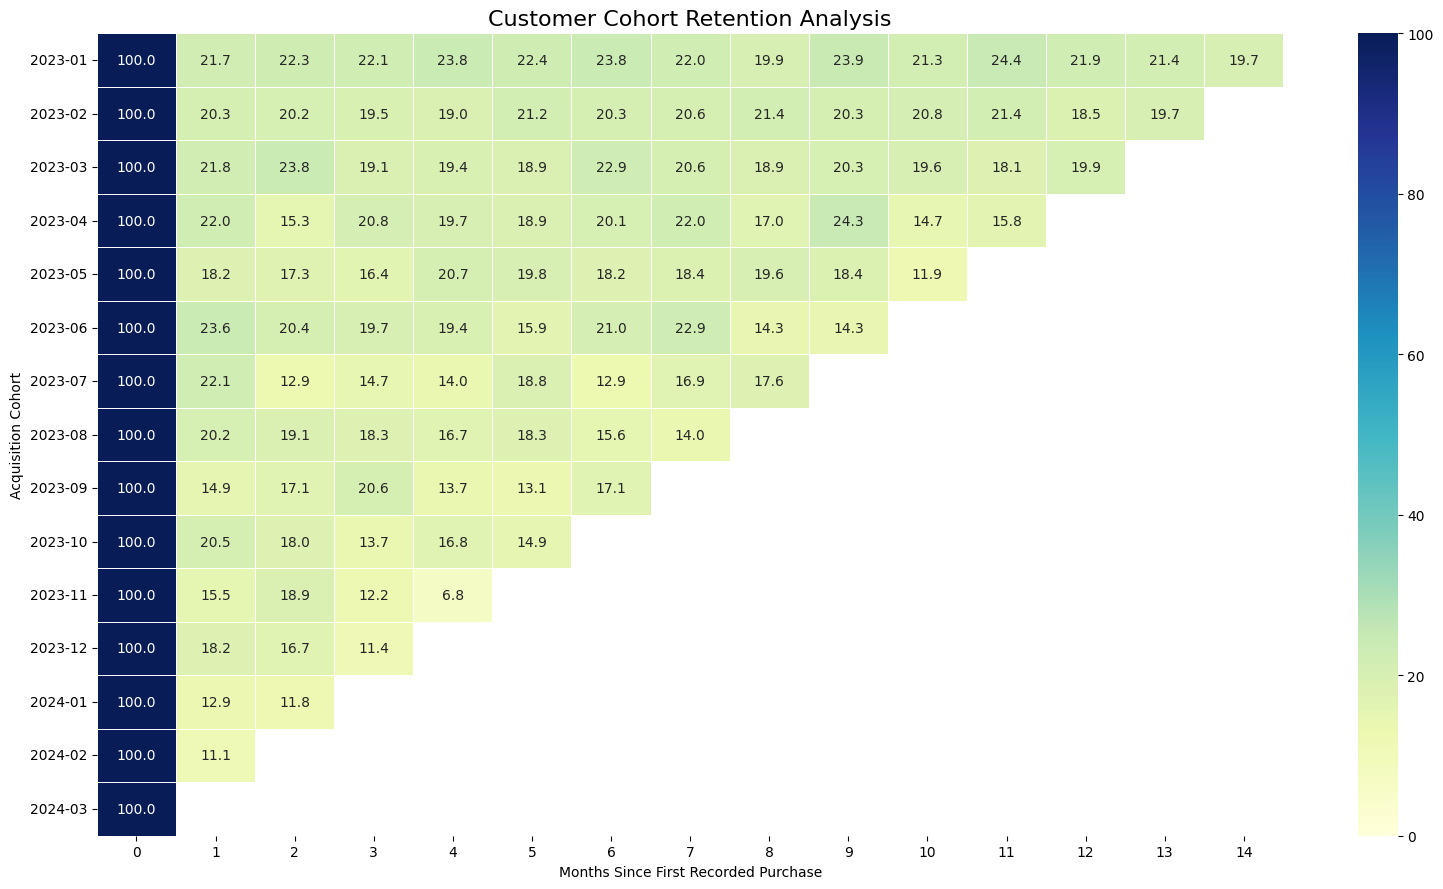

In [77]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 9))

sns.heatmap(cohort_retention, annot=True, fmt=".1f", cmap="YlGnBu", vmin=0, vmax=100, linewidths=0.5,mask=cohort_retention.isna())

plt.title("Customer Cohort Retention Analysis", fontsize=16)
plt.xlabel("Months Since First Recorded Purchase")
plt.ylabel("Acquisition Cohort")

plt.tight_layout()
plt.show()

# X-axis: Months Since First Recorded Purchase
# Y-axis: Acquisition Cohort

In [78]:
# Compare cohorts at equivalent lifecycle stages

comparison_months = [1, 3, 6]

cohort_comparison = cohort_retention[
    [month for month in comparison_months
     if month in cohort_retention.columns]
].copy()

cohort_comparison.round(2)

Months_Since_Acquisition,1,3,6
Cohort_Month,,,
2023-01,21.68,22.08,23.78
2023-02,20.32,19.52,20.32
2023-03,21.76,19.10,22.92
2023-04,22.01,20.85,20.08
2023-05,18.20,16.40,18.20
2023-06,23.57,19.75,21.02
2023-07,22.06,14.71,12.87
2023-08,20.23,18.29,15.56
2023-09,14.86,20.57,17.14


In [79]:
# Summarise Month 1 retention across acquisition cohorts

month_1_retention = cohort_retention[1].dropna()

print("Number of cohorts:", len(month_1_retention))

print("Average Month 1 retention across cohorts:", round(month_1_retention.mean(), 2),"%")

print("Median Month 1 retention:", round(month_1_retention.median(), 2),"%")

print("Lowest Month 1 retention:", round(month_1_retention.min(), 2),"%")

print("Highest Month 1 retention:", round(month_1_retention.max(), 2),"%")

Number of cohorts: 14
Average Month 1 retention across cohorts: 18.78 %
Median Month 1 retention: 20.28 %
Lowest Month 1 retention: 11.11 %
Highest Month 1 retention: 23.57 %


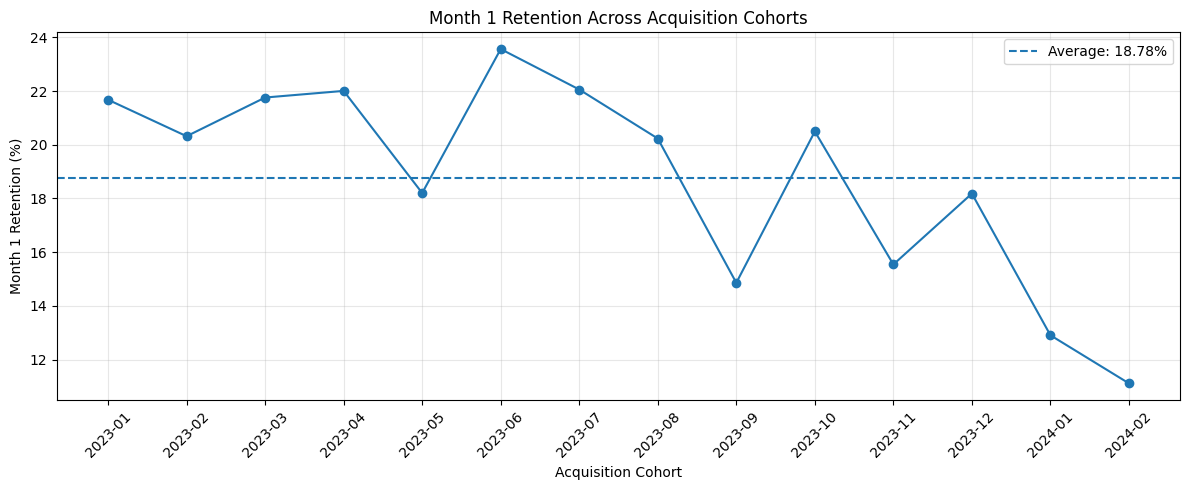

In [80]:
import matplotlib.pyplot as plt

# Extract Month 1 retention for each acquisition cohort
month_1_trend = cohort_retention[1].dropna()

# Plot retention over time
plt.figure(figsize=(12, 5))

plt.plot(month_1_trend.index.astype(str), month_1_trend.values, marker="o")

plt.axhline(month_1_trend.mean(), linestyle="--", label=f"Average: {month_1_trend.mean():.2f}%")

plt.title("Month 1 Retention Across Acquisition Cohorts")
plt.xlabel("Acquisition Cohort")
plt.ylabel("Month 1 Retention (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Month 1 repeat-purchase rates fluctuated across acquisition cohorts, with retention generally lower among the most recent cohorts in the dataset. The February 2024 cohort recorded the lowest observed rate at 11.11%, compared with 23.57% for June 2023. This pattern warrants further investigation to determine whether the decline reflects a sustained change in customer behaviour or variation between individual cohorts.

In [81]:
# Ensuring the transaction dates are datetime values
df["Date"] = pd.to_datetime(df["Date"])

# Finding each customer's first purchase date
first_purchase_dates = (
    df.groupby("Customer_ID")["Date"]
    .min()
    .rename("First_Purchase_Date")
)

# Creating a customer-level dataset
customer_trend = first_purchase_dates.reset_index()

# Assigning each customer to their acquisition month
customer_trend["Cohort_Month"] = (
    customer_trend["First_Purchase_Date"].dt.to_period("M")
)

# Inspecting the results
customer_trend.head(10)

,Customer_ID,First_Purchase_Date,Cohort_Month
0,CUST_00001,2023-05-29,2023-05
1,CUST_00002,2023-05-11,2023-05
2,CUST_00003,2023-02-27,2023-02
3,CUST_00004,2024-02-13,2024-02
4,CUST_00005,2023-03-16,2023-03
5,CUST_00006,2023-07-24,2023-07
6,CUST_00007,2024-01-05,2024-01
7,CUST_00008,2023-09-14,2023-09
8,CUST_00009,2024-02-16,2024-02
9,CUST_00010,2023-08-15,2023-08


In [82]:
# Create a transaction-level copy for the retention calculation
trend_transactions = df.copy()

# Convert transaction dates to monthly periods
trend_transactions["Order_Month"] = (trend_transactions["Date"].dt.to_period("M"))

# Merge acquisition months into the transaction dataset
trend_transactions = trend_transactions.merge(customer_trend[["Customer_ID", "Cohort_Month"]],on="Customer_ID",how="left")

# Identify each customer's Month 1
trend_transactions["Month_1"] = (trend_transactions["Cohort_Month"] + 1)

# Check the results
trend_transactions[["Customer_ID", "Date", "Cohort_Month", "Order_Month", "Month_1"]].head(10)

,Customer_ID,Date,Cohort_Month,Order_Month,Month_1
0,CUST_00001,2023-05-29,2023-05,2023-05,2023-06
1,CUST_00001,2023-10-12,2023-05,2023-10,2023-06
2,CUST_00001,2023-12-05,2023-05,2023-12,2023-06
3,CUST_00002,2023-05-11,2023-05,2023-05,2023-06
4,CUST_00002,2023-06-16,2023-05,2023-06,2023-06
5,CUST_00003,2023-02-27,2023-02,2023-02,2023-03
6,CUST_00003,2024-01-03,2023-02,2024-01,2023-03
7,CUST_00004,2024-02-13,2024-02,2024-02,2024-03
8,CUST_00005,2023-03-16,2023-03,2023-03,2023-04
9,CUST_00005,2023-06-12,2023-03,2023-06,2023-04


In [83]:
# Identifying the last month with observed transactions
last_observed_month = df["Date"].dt.to_period("M").max()

# Excluding customers whose Month 1 cannot be fully observed
eligible_trend_customers = customer_trend[customer_trend["Cohort_Month"] + 1 <= last_observed_month].copy()

# Identifying each eligible customer's Month 1
eligible_trend_customers["Month_1"] = (eligible_trend_customers["Cohort_Month"] + 1)

# Identifying customers who made a purchase in Month 1
month_1_purchases = (trend_transactions[trend_transactions["Order_Month"]== trend_transactions["Month_1"]]["Customer_ID"].unique())

# Creating the binary retention outcome
eligible_trend_customers["Retained_Month_1"] = (eligible_trend_customers["Customer_ID"].isin(month_1_purchases).astype(int))

# Inspecting the results
eligible_trend_customers.head(10)

,Customer_ID,First_Purchase_Date,Cohort_Month,Month_1,Retained_Month_1
0,CUST_00001,2023-05-29,2023-05,2023-06,0
1,CUST_00002,2023-05-11,2023-05,2023-06,1
2,CUST_00003,2023-02-27,2023-02,2023-03,0
3,CUST_00004,2024-02-13,2024-02,2024-03,0
4,CUST_00005,2023-03-16,2023-03,2023-04,0
5,CUST_00006,2023-07-24,2023-07,2023-08,1
6,CUST_00007,2024-01-05,2024-01,2024-02,0
7,CUST_00008,2023-09-14,2023-09,2023-10,1
8,CUST_00009,2024-02-16,2024-02,2024-03,0
9,CUST_00010,2023-08-15,2023-08,2023-09,0


In [84]:
# Summarising Month 1 retention by acquisition cohort

trend_summary = (eligible_trend_customers.groupby("Cohort_Month")["Retained_Month_1"].agg(["count", "sum", "mean"]).reset_index())

# Renaming columns for clarity
trend_summary = trend_summary.rename(columns={"count": "Eligible_Customers","sum": "Retained_Customers","mean": "Retention_Rate"})

# Converting retention rate to a percentage
trend_summary["Retention_Rate"] *= 100

# Displaying the results
trend_summary.round(2)

,Cohort_Month,Eligible_Customers,Retained_Customers,Retention_Rate
0,2023-01,1001,217,21.68
1,2023-02,753,153,20.32
2,2023-03,602,131,21.76
3,2023-04,518,114,22.01
4,2023-05,445,81,18.20
5,2023-06,314,74,23.57
6,2023-07,272,60,22.06
7,2023-08,257,52,20.23
8,2023-09,175,26,14.86
9,2023-10,161,33,20.50


In [85]:
# Creating a numerical acquisition-month predictor

eligible_trend_customers["Acquisition_Month_Index"] = ((eligible_trend_customers["Cohort_Month"].dt.year - 2023) * 12 + eligible_trend_customers["Cohort_Month"].dt.month- 1)

# Inspecting the variables for regression
eligible_trend_customers[["Customer_ID", "Cohort_Month", "Acquisition_Month_Index","Retained_Month_1"]].head(10)

,Customer_ID,Cohort_Month,Acquisition_Month_Index,Retained_Month_1
0,CUST_00001,2023-05,4,0
1,CUST_00002,2023-05,4,1
2,CUST_00003,2023-02,1,0
3,CUST_00004,2024-02,13,0
4,CUST_00005,2023-03,2,0
5,CUST_00006,2023-07,6,1
6,CUST_00007,2024-01,12,0
7,CUST_00008,2023-09,8,1
8,CUST_00009,2024-02,13,0
9,CUST_00010,2023-08,7,0


In [86]:
import statsmodels.api as sm

# Define the predictor and outcome
X = eligible_trend_customers[["Acquisition_Month_Index"]]
y = eligible_trend_customers["Retained_Month_1"]

# Add the intercept
X = sm.add_constant(X)

# Fit the logistic regression model
trend_model = sm.Logit(y, X).fit()

# Display the regression results
print(trend_model.summary())

Optimization terminated successfully.
         Current function value: 0.504990
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:       Retained_Month_1   No. Observations:                 4943
Model:                          Logit   Df Residuals:                     4941
Method:                           MLE   Df Model:                            1
Date:                Fri, 13 Nov 2026   Pseudo R-squ.:                0.001592
Time:                        15:41:35   Log-Likelihood:                -2496.2
converged:                       True   LL-Null:                       -2500.1
Covariance Type:            nonrobust   LLR p-value:                  0.004785
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                      -1.2574      0.051    -24.802      0.000      -1.357   

| Finding                                                                                       | Business interpretation                                                                                                                                |
| --------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------ |
| Month 1 retention has a statistically significant negative association with acquisition time. | More recently acquired cohorts tended to be less likely to make a repeat purchase in the following calendar month.                                     |
| The estimated odds decrease by approximately 2.9% per acquisition month.                      | The downward trend is measurable, although the odds ratio is relatively close to 1 each month.                                                         |
| The pseudo R-squared is very small.                                                           | Acquisition time alone explains little of the observed differences in retention. Further investigation is needed to understand the underlying factors. |

### Estimating Predicted Retention Probabilities

In [87]:
# Identifying the earliest and latest eligible acquisition months

first_month = eligible_trend_customers["Acquisition_Month_Index"].min()
last_month = eligible_trend_customers["Acquisition_Month_Index"].max()

first_cohort = eligible_trend_customers["Cohort_Month"].min()
last_cohort = eligible_trend_customers["Cohort_Month"].max()


# Creating prediction data for both acquisition months

prediction_data = pd.DataFrame({
    "Acquisition_Month_Index": [first_month, last_month]
})

# Adding the intercept required by the regression model
prediction_data = sm.add_constant(prediction_data, has_constant="add")


# Generating predicted retention probabilities

predicted_retention = trend_model.predict(prediction_data)


# Displaying the results

prediction_results = pd.DataFrame({
    "Acquisition_Cohort": [str(first_cohort), str(last_cohort)],
    "Predicted_Month_1_Retention": predicted_retention.values * 100
})

prediction_results["Predicted_Month_1_Retention"] = (
    prediction_results["Predicted_Month_1_Retention"].round(2)
)

prediction_results

,Acquisition_Cohort,Predicted_Month_1_Retention
0,2023-01,22.14
1,2024-02,16.26


In [88]:
# Calculating the predicted retention change

retention_change = (
    prediction_results["Predicted_Month_1_Retention"].iloc[1]
    - prediction_results["Predicted_Month_1_Retention"].iloc[0]
)

print(f"Predicted retention change: {retention_change:.2f} percentage points")

Predicted retention change: -5.88 percentage points


### Modelling the Relationship Between Acquisition Month and Month 1 Retention

The logistic regression identified a statistically significant negative relationship between acquisition month and Month 1 retention (coefficient = -0.0293, p = 0.005).

The model estimated that Month 1 retention declined from approximately 22.14% for the January 2023 acquisition cohort to 16.26% for the February 2024 cohort, representing a decrease of 5.88 percentage points.

However, the model's pseudo R-squared of 0.001592 indicates very limited explanatory power. Although acquisition month is statistically associated with retention, it explains very little of the variation in customer retention.

**Business implication:** The declining retention pattern suggests that the company should investigate changes in customer acquisition and engagement over time. However, this analysis does not establish the underlying causes of the decline or demonstrate a causal relationship.

# Comparing Discount Performance Across Cohorts

Does the retention performance of discounted customers change across acquisition cohorts?

In [89]:
# print("Columns:", first_purchase.columns.tolist())
# print("Index name:", first_purchase.index.name)
# print(first_purchase.head()

In [90]:
first_purchase = first_purchase.reset_index()

In [91]:
# Attaching first-purchase discount status to eligible cohort customers

cohort_discount_data = eligible_trend_customers.merge(
    first_purchase[["Customer_ID", "Has_Discount"]],
    on="Customer_ID",
    how="left",
    validate="one_to_one"
)

# Checking the results

cohort_discount_data[
    ["Customer_ID", "Cohort_Month", "Has_Discount", "Retained_Month_1"]
].head(10)

,Customer_ID,Cohort_Month,Has_Discount,Retained_Month_1
0,CUST_00001,2023-05,False,0
1,CUST_00002,2023-05,True,1
2,CUST_00003,2023-02,False,0
3,CUST_00004,2024-02,True,0
4,CUST_00005,2023-03,False,0
5,CUST_00006,2023-07,False,1
6,CUST_00007,2024-01,True,0
7,CUST_00008,2023-09,True,1
8,CUST_00009,2024-02,False,0
9,CUST_00010,2023-08,False,0


In [92]:
# Calculating Month 1 retention by acquisition cohort and discount status

cohort_discount_retention = (
    cohort_discount_data
    .groupby(["Cohort_Month", "Has_Discount"])
    ["Retained_Month_1"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Converting retention rates into percentages

cohort_discount_retention["Retention_Rate"] = (
    cohort_discount_retention["mean"] * 100
)

# Renaming columns for clarity

cohort_discount_retention = cohort_discount_retention.rename(
    columns={
        "count": "Eligible_Customers",
        "sum": "Retained_Customers"
    }
)

cohort_discount_retention.round(2)

,Cohort_Month,Has_Discount,Eligible_Customers,Retained_Customers,mean,Retention_Rate
0,2023-01,False,616,136,0.22,22.08
1,2023-01,True,385,81,0.21,21.04
2,2023-02,False,457,82,0.18,17.94
3,2023-02,True,296,71,0.24,23.99
4,2023-03,False,376,77,0.20,20.48
5,2023-03,True,226,54,0.24,23.89
6,2023-04,False,319,65,0.20,20.38
7,2023-04,True,199,49,0.25,24.62
8,2023-05,False,264,58,0.22,21.97
9,2023-05,True,181,23,0.13,12.71


In [93]:
# Comparing discounted and non-discounted retention

cohort_discount_pivot = cohort_discount_retention.pivot(
    index="Cohort_Month",
    columns="Has_Discount",
    values="Retention_Rate"
)

# Renaming columns

cohort_discount_pivot.columns = ["No_Discount", "Discount"]

# Calculating retention lift in percentage points

cohort_discount_pivot["Retention_Lift_pp"] = (
    cohort_discount_pivot["Discount"]
    - cohort_discount_pivot["No_Discount"]
)

cohort_discount_pivot.round(2)

,No_Discount,Discount,Retention_Lift_pp
Cohort_Month,,,
2023-01,22.08,21.04,-1.04
2023-02,17.94,23.99,6.04
2023-03,20.48,23.89,3.42
2023-04,20.38,24.62,4.25
2023-05,21.97,12.71,-9.26
2023-06,23.86,23.08,-0.78
2023-07,23.03,20.21,-2.82
2023-08,25.31,11.58,-13.73
2023-09,10.26,24.14,13.88


### Conducting Two-Proportion Z-Tests Across Acquisition Cohorts

In [94]:
from statsmodels.stats.proportion import proportions_ztest

# Storing the statistical test results
cohort_test_results = []

# Testing each acquisition cohort separately

for cohort in cohort_discount_retention["Cohort_Month"].unique():

    cohort_data = cohort_discount_retention[
        cohort_discount_retention["Cohort_Month"] == cohort
    ]

    # Extracting retained customers
    retained = cohort_data.set_index("Has_Discount")["Retained_Customers"]

    # Extracting  eligible customer counts
    sample_sizes = cohort_data.set_index("Has_Discount")["Eligible_Customers"]

    # Discount group first, non-discount group second
    successes = [
        retained.get(True, 0),
        retained.get(False, 0)
    ]

    samples = [
        sample_sizes.get(True, 0),
        sample_sizes.get(False, 0)
    ]

    # Checking whether both groups have sufficient observations
    if min(samples) == 0:
        continue

    # Two-proportion Z-test
    z_stat, p_value = proportions_ztest(
        successes,
        samples
    )

    cohort_test_results.append({
        "Cohort_Month": cohort,
        "Discount_Customers": samples[0],
        "No_Discount_Customers": samples[1],
        "Discount_Retained": successes[0],
        "No_Discount_Retained": successes[1],
        "Z_Statistic": z_stat,
        "P_Value": p_value
    })

# Converting results into a DataFrame

cohort_test_results = pd.DataFrame(cohort_test_results)

cohort_test_results

,Cohort_Month,Discount_Customers,No_Discount_Customers,Discount_Retained,No_Discount_Retained,Z_Statistic,P_Value
0,2023-01,385,616,81,136,-0.388105,0.697938
1,2023-02,296,457,71,82,2.013075,0.044107
2,2023-03,226,376,54,77,0.983335,0.325443
3,2023-04,199,319,49,65,1.134801,0.256459
4,2023-05,181,264,23,58,-2.487465,0.012866
5,2023-06,117,197,27,47,-0.157648,0.874734
6,2023-07,94,178,19,41,-0.533592,0.593624
7,2023-08,95,162,11,41,-2.644650,0.008178
8,2023-09,58,117,14,12,2.430430,0.015081
9,2023-10,67,94,14,19,0.105784,0.915754


In [95]:
from statsmodels.stats.multitest import multipletests

# Applying Holm correction

cohort_test_results["Adjusted_P_Value"] = multipletests(
    cohort_test_results["P_Value"],
    method="holm"
)[1]

# Identifying statistically significant results

cohort_test_results["Significant_After_Correction"] = (
    cohort_test_results["Adjusted_P_Value"] < 0.05
)

# Sorting by adjusted p-value

cohort_test_results.sort_values(
    "Adjusted_P_Value"
).round(4)

,Cohort_Month,Discount_Customers,No_Discount_Customers,Discount_Retained,No_Discount_Retained,Z_Statistic,P_Value,Adjusted_P_Value,Significant_After_Correction
7,2023-08,95,162,11,41,-2.6446,0.0082,0.1145,False
4,2023-05,181,264,23,58,-2.4875,0.0129,0.1673,False
8,2023-09,58,117,14,12,2.4304,0.0151,0.1810,False
1,2023-02,296,457,71,82,2.0131,0.0441,0.4852,False
3,2023-04,199,319,49,65,1.1348,0.2565,1.0000,False
2,2023-03,226,376,54,77,0.9833,0.3254,1.0000,False
5,2023-06,117,197,27,47,-0.1576,0.8747,1.0000,False
0,2023-01,385,616,81,136,-0.3881,0.6979,1.0000,False
6,2023-07,94,178,19,41,-0.5336,0.5936,1.0000,False
9,2023-10,67,94,14,19,0.1058,0.9158,1.0000,False


#### Conducting Fisher's Exact Tests

In [96]:
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

# Storing Fisher's Exact Test results
fisher_results = []

for _, row in cohort_test_results.iterrows():

    # Constructing the 2x2 contingency table

    contingency_table = [
        [
            row["Discount_Retained"],
            row["Discount_Customers"] - row["Discount_Retained"]
        ],
        [
            row["No_Discount_Retained"],
            row["No_Discount_Customers"] - row["No_Discount_Retained"]
        ]
    ]

    # Performing Fisher's Exact Test

    odds_ratio, p_value = fisher_exact(
        contingency_table,
        alternative="two-sided"
    )

    fisher_results.append({
        "Cohort_Month": row["Cohort_Month"],
        "Odds_Ratio": odds_ratio,
        "Fisher_P_Value": p_value
    })

# Creating results DataFrame

fisher_results = pd.DataFrame(fisher_results)

# Applying Holm correction

fisher_results["Adjusted_P_Value"] = multipletests(
    fisher_results["Fisher_P_Value"],
    method="holm"
)[1]

# Identifying statistically significant differences

fisher_results["Significant_After_Correction"] = (
    fisher_results["Adjusted_P_Value"] < 0.05
)

fisher_results.sort_values(
    "Adjusted_P_Value"
).round(4)

,Cohort_Month,Odds_Ratio,Fisher_P_Value,Adjusted_P_Value,Significant_After_Correction
7,2023-08,0.3865,0.0097,0.1356,False
4,2023-05,0.5170,0.0127,0.1650,False
8,2023-09,2.7841,0.0228,0.2732,False
1,2023-02,1.4431,0.0514,0.5652,False
3,2023-04,1.2765,0.2763,1.0000,False
2,2023-03,1.2191,0.3588,1.0000,False
5,2023-06,0.9574,0.8917,1.0000,False
0,2023-01,0.9404,0.7526,1.0000,False
6,2023-07,0.8465,0.6467,1.0000,False
9,2023-10,1.0427,1.0000,1.0000,False


### Interpreting Discount Performance Across Acquisition Cohorts

The cohort-level analysis revealed considerable variation in the relationship between first-purchase discounts and subsequent customer retention. Some acquisition cohorts recorded higher retention among discounted customers, while others experienced lower retention compared with non-discounted customers.

Two-proportion Z-tests initially identified four cohorts with statistically significant differences. However, after applying the Holm correction for multiple comparisons, none remained statistically significant.

To validate these findings, Fisher's Exact Test was also performed. Although August, May and September 2023 showed notable differences in their observed retention odds, none remained statistically significant after multiple-comparison correction.

**Business Implication:** There is insufficient statistical evidence to conclude that first-purchase discounts consistently improve customer retention across acquisition cohorts. The variation between cohorts suggests that discount effectiveness may depend on other customer or acquisition characteristics. However, the current analysis does not establish which factors explain these differences.

The findings reinforce the need to evaluate discount effectiveness beyond observed retention rates before making decisions about promotional spending.

# Evaluating First-Purchase Discount Effectiveness

#### Comparing Repeat-Purchase Behaviour by First-Purchase Discount Status

In [97]:
# Calculating the total number of orders per customer

customer_orders = (
    df.groupby("Customer_ID")["Order_ID"]
    .nunique()
    .reset_index(name="Total_Orders")
)

# Attaching first-purchase discount status

discount_repeat_analysis = customer_orders.merge(
    first_purchase[["Customer_ID", "Has_Discount"]],
    on="Customer_ID",
    how="left",
    validate="one_to_one"
)

# Identifying repeat purchasers

discount_repeat_analysis["Repeat_Purchaser"] = (
    discount_repeat_analysis["Total_Orders"] > 1
).astype(int)

# Summarising purchasing behaviour by discount status

repeat_summary = (
    discount_repeat_analysis
    .groupby("Has_Discount")
    .agg(
        Total_Customers=("Customer_ID", "count"),
        Repeat_Customers=("Repeat_Purchaser", "sum"),
        Repeat_Purchase_Rate=("Repeat_Purchaser", "mean"),
        Average_Orders=("Total_Orders", "mean"),
        Median_Orders=("Total_Orders", "median")
    )
    .reset_index()
)

# Converting repeat purchase rate to percentage

repeat_summary["Repeat_Purchase_Rate"] *= 100

repeat_summary.round(2)

,Has_Discount,Total_Customers,Repeat_Customers,Repeat_Purchase_Rate,Average_Orders,Median_Orders
0,False,3092,2520,81.50,3.38,3.0
1,True,1908,1588,83.23,3.45,3.0


In [98]:
# Testing the statistical significance of repeat purchase rates
from statsmodels.stats.proportion import proportions_ztest

# Number of repeat purchasers
successes = [
    1588,  # Discount customers
    2520   # Non-discount customers
]

# Total customers in each group
samples = [
    1908,
    3092
]

# Perform two-proportion Z-test
z_stat, p_value = proportions_ztest(
    successes,
    samples
)

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("The difference is statistically significant.")
else:
    print("The difference is not statistically significant.")

Z-statistic: 1.5503
P-value: 0.1211
The difference is not statistically significant.


### Interpreting Repeat Purchasing by First-Purchase Discount Status

Discounted customers recorded a repeat purchase rate of 83.23%, compared with 81.50% among non-discounted customers, representing an observed difference of 1.73 percentage points.

Discounted customers also recorded a slightly higher average number of orders (3.45 versus 3.38). However, both groups had the same median number of orders (3).

A two-proportion Z-test produced a p-value of 0.1211, exceeding the 0.05 significance threshold. Therefore, the observed difference in repeat purchase rates is not statistically significant.

**Business Implication:** Although discounted customers demonstrated marginally higher repeat-purchasing activity, there is insufficient statistical evidence that first-purchase discounts meaningfully improve repeat purchasing. The programme's effectiveness therefore remains uncertain, and its financial justification requires further investigation.

# Evaluating Customer Economics
Does the incremental customer activity and revenue justify the cost of offering first-purchase discounts?

In [99]:
# Inspecting transaction-level revenue and discount information

df[
    [
        "Customer_ID",
        "Order_ID",
        "Unit_Price",
        "Quantity",
        "Discount_Amount",
        "Total_Amount"
    ]
].head(10)

,Customer_ID,Order_ID,Unit_Price,Quantity,Discount_Amount,Total_Amount
0,CUST_00001,ORD_000001-1,29.18,1,0.00,29.18
1,CUST_00001,ORD_000001-2,644.40,1,138.05,506.35
2,CUST_00001,ORD_000001-3,332.82,5,0.00,1664.10
3,CUST_00002,ORD_000002-1,69.30,5,71.05,275.45
4,CUST_00002,ORD_000002-2,178.15,3,0.00,534.45
5,CUST_00003,ORD_000003-1,198.28,2,0.00,396.56
6,CUST_00003,ORD_000003-2,526.85,5,0.00,2634.25
7,CUST_00004,ORD_000004-1,96.20,5,97.78,383.22
8,CUST_00005,ORD_000005-1,533.67,3,0.00,1601.01
9,CUST_00005,ORD_000005-2,73.06,4,0.00,292.24


In [100]:
# Comparing transaction revenue against calculated gross sales

df["Gross_Sales_Check"] = df["Unit_Price"] * df["Quantity"]

df[[ "Gross_Sales_Check", "Discount_Amount", "Total_Amount"]].head(10)

,Gross_Sales_Check,Discount_Amount,Total_Amount
0,29.18,0.00,29.18
1,644.40,138.05,506.35
2,1664.10,0.00,1664.10
3,346.50,71.05,275.45
4,534.45,0.00,534.45
5,396.56,0.00,396.56
6,2634.25,0.00,2634.25
7,481.00,97.78,383.22
8,1601.01,0.00,1601.01
9,292.24,0.00,292.24


### Calculating Customer-Level Financial Metrics

In [101]:
# Calculating customer-level financial metrics

customer_economics = (
    df.groupby("Customer_ID")
    .agg(
        Total_Gross_Sales=("Gross_Sales_Check", "sum"),
        Total_Discount=("Discount_Amount", "sum"),
        Total_Net_Revenue=("Total_Amount", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

# Calculating average order value

customer_economics["Average_Order_Value"] = (
    customer_economics["Total_Net_Revenue"] /
    customer_economics["Total_Orders"]
)

# Attaching first-purchase discount status

customer_economics = customer_economics.merge(
    first_purchase[["Customer_ID", "Has_Discount"]],
    on="Customer_ID",
    how="left",
    validate="one_to_one"
)

# Inspecting the customer-level dataset

customer_economics.head(10)

,Customer_ID,Total_Gross_Sales,Total_Discount,Total_Net_Revenue,Total_Orders,Average_Order_Value,Has_Discount
0,CUST_00001,2337.68,138.05,2199.63,3,733.210000,False
1,CUST_00002,880.95,71.05,809.90,2,404.950000,True
2,CUST_00003,3030.81,0.00,3030.81,2,1515.405000,False
3,CUST_00004,481.00,97.78,383.22,1,383.220000,True
4,CUST_00005,2422.73,0.00,2422.73,3,807.576667,False
5,CUST_00006,1258.60,12.77,1245.83,3,415.276667,False
6,CUST_00007,1474.50,142.95,1331.55,1,1331.550000,True
7,CUST_00008,5792.44,190.15,5602.29,3,1867.430000,True
8,CUST_00009,470.86,0.00,470.86,1,470.860000,False
9,CUST_00010,1421.16,0.00,1421.16,3,473.720000,False


#### Comparing Customer Financial Performance

Do customers who received first-purchase discounts generate more revenue for the business?

In [102]:
# Comparing customer financial performance by discount status

economics_summary = (
    customer_economics
    .groupby("Has_Discount")
    .agg(
        Customers=("Customer_ID", "count"),

        Average_Gross_Sales=("Total_Gross_Sales", "mean"),

        Average_Discount=("Total_Discount", "mean"),

        Average_Net_Revenue=("Total_Net_Revenue", "mean"),

        Median_Net_Revenue=("Total_Net_Revenue", "median"),

        Average_Orders=("Total_Orders", "mean"),

        Average_Order_Value=("Average_Order_Value", "mean")
    )
    .reset_index()
)

economics_summary.round(2)

,Has_Discount,Customers,Average_Gross_Sales,Average_Discount,Average_Net_Revenue,Median_Net_Revenue,Average_Orders,Average_Order_Value
0,False,3092,4618.78,165.64,4453.14,2577.38,3.38,1312.80
1,True,1908,4553.25,355.17,4198.08,2381.93,3.45,1181.99


# Evaluating Repeat-Purchase Revenue
Do customers who receive first-purchase discounts generate more revenue from subsequent purchases?

In [103]:
# Creating a transaction-level copy
revenue_analysis = df.copy()

# Sorting transactions chronologically for each customer
revenue_analysis = revenue_analysis.sort_values(
    ["Customer_ID", "Date", "Order_ID"]
)

# Identifying each customer's first recorded transaction
revenue_analysis["Order_Number"] = (
    revenue_analysis.groupby("Customer_ID").cumcount() + 1
)

# Classifying transactions
revenue_analysis["Purchase_Type"] = (
    revenue_analysis["Order_Number"]
    .apply(lambda x: "First Purchase" if x == 1 else "Repeat Purchase")
)

# Inspecting the results
revenue_analysis[
    [
        "Customer_ID",
        "Order_ID",
        "Date",
        "Order_Number",
        "Purchase_Type",
        "Total_Amount"
    ]
].head(15)

,Customer_ID,Order_ID,Date,Order_Number,Purchase_Type,Total_Amount
0,CUST_00001,ORD_000001-1,2023-05-29,1,First Purchase,29.18
1,CUST_00001,ORD_000001-2,2023-10-12,2,Repeat Purchase,506.35
2,CUST_00001,ORD_000001-3,2023-12-05,3,Repeat Purchase,1664.10
3,CUST_00002,ORD_000002-1,2023-05-11,1,First Purchase,275.45
4,CUST_00002,ORD_000002-2,2023-06-16,2,Repeat Purchase,534.45
5,CUST_00003,ORD_000003-1,2023-02-27,1,First Purchase,396.56
6,CUST_00003,ORD_000003-2,2024-01-03,2,Repeat Purchase,2634.25
7,CUST_00004,ORD_000004-1,2024-02-13,1,First Purchase,383.22
8,CUST_00005,ORD_000005-1,2023-03-16,1,First Purchase,1601.01
9,CUST_00005,ORD_000005-2,2023-06-12,2,Repeat Purchase,292.24


#### Comparing Repeat-Purchase Revenue by First-Purchase Discount Status

In [104]:
# Calculating repeat-purchase revenue per customer

repeat_revenue = (
    revenue_analysis[
        revenue_analysis["Purchase_Type"] == "Repeat Purchase"
    ]
    .groupby("Customer_ID")
    .agg(
        Repeat_Revenue=("Total_Amount", "sum"),
        Repeat_Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

# Attaching first-purchase discount status
# Including customers who never made another purchase

customer_repeat_revenue = first_purchase[
    ["Customer_ID", "Has_Discount"]
].merge(
    repeat_revenue,
    on="Customer_ID",
    how="left"
)

# Replacing missing repeat activity with zero

customer_repeat_revenue[
    ["Repeat_Revenue", "Repeat_Orders"]
] = customer_repeat_revenue[
    ["Repeat_Revenue", "Repeat_Orders"]
].fillna(0)

# Comparing repeat-purchase performance

repeat_revenue_summary = (
    customer_repeat_revenue
    .groupby("Has_Discount")
    .agg(
        Customers=("Customer_ID", "count"),
        Repeat_Customers=("Repeat_Orders", lambda x: (x > 0).sum()),
        Total_Repeat_Revenue=("Repeat_Revenue", "sum"),
        Average_Repeat_Revenue=("Repeat_Revenue", "mean"),
        Median_Repeat_Revenue=("Repeat_Revenue", "median"),
        Average_Repeat_Orders=("Repeat_Orders", "mean")
    )
    .reset_index()
)

repeat_revenue_summary.round(2)

,Has_Discount,Customers,Repeat_Customers,Total_Repeat_Revenue,Average_Repeat_Revenue,Median_Repeat_Revenue,Average_Repeat_Orders
0,False,3092,2520,9658026.88,3123.55,1167.38,2.38
1,True,1908,1588,5821176.28,3050.93,1189.14,2.45


### Testing for Differences in Repeat-Purchase Revenue

In [105]:
from scipy.stats import mannwhitneyu

# Keep only customers who made repeat purchases
repeat_purchasers = customer_repeat_revenue[
    customer_repeat_revenue["Repeat_Orders"] > 0
].copy()

# Separate repeat revenue by discount status
discount_revenue = repeat_purchasers.loc[
    repeat_purchasers["Has_Discount"] == True,
    "Repeat_Revenue"
]

non_discount_revenue = repeat_purchasers.loc[
    repeat_purchasers["Has_Discount"] == False,
    "Repeat_Revenue"
]

# Perform Mann-Whitney U test
u_stat, p_value = mannwhitneyu(
    discount_revenue,
    non_discount_revenue,
    alternative="two-sided"
)

print("Mann-Whitney U Test: Repeat Revenue Among Repeat Purchasers")
print("-" * 60)

print("Discounted repeat purchasers:", len(discount_revenue))
print("Non-discounted repeat purchasers:", len(non_discount_revenue))

print("U-statistic:", round(u_stat, 2))
print("P-value:", round(p_value, 6))

if p_value < 0.05:
    print("The difference is statistically significant.")
else:
    print("Insufficient evidence of a statistically significant difference.")

u_stat, p_value = mannwhitneyu(
    discount_revenue,
    non_discount_revenue,
    alternative="two-sided"
)

print("Mann-Whitney U Test: Repeat Revenue")
print("-----------------------------------")

print(f"Discounted customers: {len(discount_revenue)}")
print(f"Non-discounted customers: {len(non_discount_revenue)}")

print(f"U-statistic: {u_stat:.2f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("The difference in repeat revenue distributions is statistically significant.")
else:
    print("There is insufficient evidence of a statistically significant difference.")

Mann-Whitney U Test: Repeat Revenue Among Repeat Purchasers
------------------------------------------------------------
Discounted repeat purchasers: 1588
Non-discounted repeat purchasers: 2520
U-statistic: 1958633.5
P-value: 0.253764
Insufficient evidence of a statistically significant difference.
Mann-Whitney U Test: Repeat Revenue
-----------------------------------
Discounted customers: 1588
Non-discounted customers: 2520
U-statistic: 1958633.50
P-value: 0.253764
There is insufficient evidence of a statistically significant difference.


### Interpreting the Statistical Comparison of Repeat-Purchase Revenue

A Mann-Whitney U test was conducted to investigate whether repeat-purchase revenue distributions differed between customers who received a first-purchase discount and those who did not.

The analysis was restricted to customers who made at least one repeat purchase, resulting in 1,588 discounted and 2,520 non-discounted customers.

The test returned a U-statistic of 1,958,633.50 and a p-value of 0.2538. Since the p-value exceeded the 0.05 significance threshold, there was insufficient evidence of a statistically significant difference between the two groups.

**Business implication:** Although non-discounted customers generated slightly higher average repeat revenue, the statistical test did not establish a meaningful difference in their repeat-purchase revenue distributions. Therefore, the available evidence does not demonstrate that first-purchase discounts improve spending among returning customers.

#### Calculating Repeat Revenue per Acquired Customer
#### Calculating Repeat Revenue per Repeat Purchaser

In [106]:
# Reconstructing customer purchasing history

# Sorting transactions chronologically
customer_orders = df.sort_values(
    ["Customer_ID", "Date", "Order_ID"]
).copy()

# Assigning purchase sequence to each customer
customer_orders["Order_Number"] = (
    customer_orders.groupby("Customer_ID").cumcount() + 1
)

# Identifying repeat purchases
customer_orders["Is_Repeat_Purchase"] = (
    customer_orders["Order_Number"] > 1
)

# Calculating repeat revenue for each customer
repeat_revenue = (
    customer_orders[
        customer_orders["Is_Repeat_Purchase"]
    ]
    .groupby("Customer_ID")
    .agg(
        Total_Repeat_Orders=("Order_ID", "count"),
        Total_Repeat_Revenue=("Total_Amount", "sum")
    )
    .reset_index()
)

repeat_revenue.head(10)

,Customer_ID,Total_Repeat_Orders,Total_Repeat_Revenue
0,CUST_00001,2,2170.45
1,CUST_00002,1,534.45
2,CUST_00003,1,2634.25
3,CUST_00005,2,821.72
4,CUST_00006,2,550.48
5,CUST_00008,2,4878.50
6,CUST_00010,2,976.97
7,CUST_00011,6,5478.65
8,CUST_00013,1,40.59
9,CUST_00014,2,475.80


In [107]:
# Creating customer-level financial dataset
# Start wi th all acquired customers
repeat_economics = first_purchase[
    ["Customer_ID", "Has_Discount"]
].merge(
    repeat_revenue,
    on="Customer_ID",
    how="left"
)

# Customers without repeat purchases have zero repeat revenue
repeat_economics[
    ["Total_Repeat_Orders", "Total_Repeat_Revenue"]
] = repeat_economics[
    ["Total_Repeat_Orders", "Total_Repeat_Revenue"]
].fillna(0)

# Identify repeat purchasers
repeat_economics["Repeat_Purchaser"] = (
    repeat_economics["Total_Repeat_Orders"] > 0
).astype(int)


In [108]:
# Comparing the two financial metrics


financial_comparison = (
    repeat_economics
    .groupby("Has_Discount")
    .agg(
        Acquired_Customers=("Customer_ID", "count"),
        Repeat_Customers=("Repeat_Purchaser", "sum"),
        Total_Repeat_Revenue=("Total_Repeat_Revenue", "sum")
    )
)

# Calculate repeat revenue per acquired customer
financial_comparison["Revenue_Per_Acquired_Customer"] = (
    financial_comparison["Total_Repeat_Revenue"] /
    financial_comparison["Acquired_Customers"]
)

# Calculate repeat revenue per repeat purchaser
financial_comparison["Revenue_Per_Repeat_Purchaser"] = (
    financial_comparison["Total_Repeat_Revenue"] /
    financial_comparison["Repeat_Customers"]
)

financial_comparison.round(2)

,Acquired_Customers,Repeat_Customers,Total_Repeat_Revenue,Revenue_Per_Acquired_Customer,Revenue_Per_Repeat_Purchaser
Has_Discount,,,,,
False,3092,2520,9658026.88,3123.55,3832.55
True,1908,1588,5821176.28,3050.93,3665.73


In [109]:
from scipy.stats import mannwhitneyu

# Separating repeat revenue by first-purchase discount status
discounted_revenue = repeat_economics.loc[
    repeat_economics["Has_Discount"] == True,
    "Total_Repeat_Revenue"
]

non_discounted_revenue = repeat_economics.loc[
    repeat_economics["Has_Discount"] == False,
    "Total_Repeat_Revenue"
]

# Performing Mann-Whitney U test
u_stat, p_value = mannwhitneyu(
    discounted_revenue,
    non_discounted_revenue,
    alternative="two-sided"
)

print("Mann-Whitney U Test: Repeat Revenue per Acquired Customer")
print("-" * 55)
print("Discounted customers:", len(discounted_revenue))
print("Non-discounted customers:", len(non_discounted_revenue))
print("U-statistic:", round(u_stat, 2))
print("P-value:", p_value)

if p_value < 0.05:
    print("The difference is statistically significant.")
else:
    print("Insufficient evidence of a statistically significant difference.")

Mann-Whitney U Test: Repeat Revenue per Acquired Customer
-------------------------------------------------------
Discounted customers: 1908
Non-discounted customers: 3092
U-statistic: 2958489.5
P-value: 0.859993291333901
Insufficient evidence of a statistically significant difference.


# Evaluating Discount Economics

In [110]:
# Inspecting first-purchase discount expenditure

first_purchase[
    [
        "Customer_ID",
        "Has_Discount",
        "Unit_Price",
        "Quantity",
        "Discount_Amount",
        "Total_Amount"
    ]
].head(10)

,Customer_ID,Has_Discount,Unit_Price,Quantity,Discount_Amount,Total_Amount
0,CUST_00001,False,29.18,1,0.00,29.18
1,CUST_00002,True,69.30,5,71.05,275.45
2,CUST_00003,False,198.28,2,0.00,396.56
3,CUST_00004,True,96.20,5,97.78,383.22
4,CUST_00005,False,533.67,3,0.00,1601.01
5,CUST_00006,False,139.07,5,0.00,695.35
6,CUST_00007,True,294.90,5,142.95,1331.55
7,CUST_00008,True,913.94,1,190.15,723.79
8,CUST_00009,False,235.43,2,0.00,470.86
9,CUST_00010,False,444.19,1,0.00,444.19


In [111]:
# Creating the final customer-level economics dataset

customer_economics_final = first_purchase[
    [
        "Customer_ID",
        "Has_Discount",
        "Unit_Price",
        "Quantity",
        "Discount_Amount",
        "Total_Amount"
    ]
].copy()

# Calculating first-purchase gross sales

customer_economics_final["First_Purchase_Gross_Sales"] = (
    customer_economics_final["Unit_Price"] *
    customer_economics_final["Quantity"]
)

# Renaming Total_Amount for clarity

customer_economics_final = customer_economics_final.rename(
    columns={
        "Total_Amount": "First_Purchase_Net_Revenue"
    }
)

# Attaching repeat-purchase revenue

customer_economics_final = customer_economics_final.merge(
    repeat_revenue[
        ["Customer_ID", "Total_Repeat_Revenue", "Total_Repeat_Orders"]
    ],
    on="Customer_ID",
    how="left"
)

# Renaming columns for consistency

customer_economics_final = customer_economics_final.rename(
    columns={
        "Total_Repeat_Revenue": "Repeat_Revenue",
        "Total_Repeat_Orders": "Repeat_Orders"
    }
)

# Customers without repeat purchases receive zero

customer_economics_final[
    ["Repeat_Revenue", "Repeat_Orders"]
] = customer_economics_final[
    ["Repeat_Revenue", "Repeat_Orders"]
].fillna(0)

# Calculating total customer revenue

customer_economics_final["Total_Customer_Revenue"] = (
    customer_economics_final["First_Purchase_Net_Revenue"] +
    customer_economics_final["Repeat_Revenue"]
)

# Inspecting the final dataset

customer_economics_final.head(10)

,Customer_ID,Has_Discount,Unit_Price,Quantity,Discount_Amount,First_Purchase_Net_Revenue,First_Purchase_Gross_Sales,Repeat_Revenue,Repeat_Orders,Total_Customer_Revenue
0,CUST_00001,False,29.18,1,0.00,29.18,29.18,2170.45,2.0,2199.63
1,CUST_00002,True,69.30,5,71.05,275.45,346.50,534.45,1.0,809.90
2,CUST_00003,False,198.28,2,0.00,396.56,396.56,2634.25,1.0,3030.81
3,CUST_00004,True,96.20,5,97.78,383.22,481.00,0.00,0.0,383.22
4,CUST_00005,False,533.67,3,0.00,1601.01,1601.01,821.72,2.0,2422.73
5,CUST_00006,False,139.07,5,0.00,695.35,695.35,550.48,2.0,1245.83
6,CUST_00007,True,294.90,5,142.95,1331.55,1474.50,0.00,0.0,1331.55
7,CUST_00008,True,913.94,1,190.15,723.79,913.94,4878.50,2.0,5602.29
8,CUST_00009,False,235.43,2,0.00,470.86,470.86,0.00,0.0,470.86
9,CUST_00010,False,444.19,1,0.00,444.19,444.19,976.97,2.0,1421.16


In [112]:
# Comparing customer economics by discount status

final_economics_summary = (
    customer_economics_final
    .groupby("Has_Discount")
    .agg(
        Customers=("Customer_ID", "count"),

        Total_Discount_Expenditure=("Discount_Amount", "sum"),

        Average_Discount=("Discount_Amount", "mean"),

        First_Purchase_Revenue=("First_Purchase_Net_Revenue", "sum"),

        Repeat_Revenue=("Repeat_Revenue", "sum"),

        Total_Revenue=("Total_Customer_Revenue", "sum"),

        Average_Revenue_Per_Customer=("Total_Customer_Revenue", "mean"),

        Repeat_Purchasers=("Repeat_Orders", lambda x: (x > 0).sum())
    )
    .reset_index()
)

# Calculate repeat purchase rate

final_economics_summary["Repeat_Purchase_Rate"] = (
    final_economics_summary["Repeat_Purchasers"] /
    final_economics_summary["Customers"]
) * 100

final_economics_summary.round(2)

,Has_Discount,Customers,Total_Discount_Expenditure,Average_Discount,First_Purchase_Revenue,Repeat_Revenue,Total_Revenue,Average_Revenue_Per_Customer,Repeat_Purchasers,Repeat_Purchase_Rate
0,False,3092,0.00,0.00,4111095.68,9658026.88,13769122.56,4453.14,2520,81.50
1,True,1908,346822.75,181.77,2188753.75,5821176.28,8009930.03,4198.08,1588,83.23


In [113]:
from scipy.stats import mannwhitneyu

# Separating total customer revenue by discount status

discounted_total_revenue = customer_economics_final.loc[
    customer_economics_final["Has_Discount"] == True,
    "Total_Customer_Revenue"
]

non_discounted_total_revenue = customer_economics_final.loc[
    customer_economics_final["Has_Discount"] == False,
    "Total_Customer_Revenue"
]

# Performing Mann-Whitney U test

u_stat, p_value = mannwhitneyu(
    discounted_total_revenue,
    non_discounted_total_revenue,
    alternative="two-sided"
)

# Displaying results

print("Mann-Whitney U Test: Total Customer Revenue")
print("--------------------------------------------")

print(f"Discounted customers: {len(discounted_total_revenue)}")
print(f"Non-discounted customers: {len(non_discounted_total_revenue)}")

print(f"U-statistic: {u_stat:.2f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("There is a statistically significant difference in total customer revenue.")
else:
    print("There is insufficient evidence of a statistically significant difference.")

Mann-Whitney U Test: Total Customer Revenue
--------------------------------------------
Discounted customers: 1908
Non-discounted customers: 3092
U-statistic: 2886296.50
P-value: 0.200526
There is insufficient evidence of a statistically significant difference.


In [114]:
# Calculating the financial impact of first-purchase discounts

discount_group = final_economics_summary.set_index("Has_Discount")

# Average revenue difference per acquired customer

revenue_difference = (
    discount_group.loc[True, "Average_Revenue_Per_Customer"]
    - discount_group.loc[False, "Average_Revenue_Per_Customer"]
)

# Discount expenditure per discounted customer

discount_per_customer = (
    discount_group.loc[True, "Total_Discount_Expenditure"]
    / discount_group.loc[True, "Customers"]
)

# Discount expenditure as a percentage of discounted customer revenue

discount_revenue_ratio = (
    discount_group.loc[True, "Total_Discount_Expenditure"]
    / discount_group.loc[True, "Total_Revenue"]
) * 100

print(f"Average revenue difference: {revenue_difference:.2f}")

print(
    f"Discount expenditure per discounted customer: "
    f"{discount_per_customer:.2f}"
)

print(
    f"Discount expenditure as % of discounted customer revenue: "
    f"{discount_revenue_ratio:.2f}%"
)

Average revenue difference: -255.07
Discount expenditure per discounted customer: 181.77
Discount expenditure as % of discounted customer revenue: 4.33%


# Estimating Revenue Recovery

In [115]:
# Calculating revenue recovery metrics

revenue_recovery = final_economics_summary.copy()

# Repeat revenue generated per naira of discount expenditure
revenue_recovery["Repeat_Revenue_Per_Discount_Naira"] = (
    revenue_recovery["Repeat_Revenue"] /
    revenue_recovery["Total_Discount_Expenditure"].replace(0, np.nan)
)

# Discount expenditure as a percentage of repeat revenue
revenue_recovery["Discount_to_Repeat_Revenue_%"] = (
    revenue_recovery["Total_Discount_Expenditure"] /
    revenue_recovery["Repeat_Revenue"]
) * 100

# Repeat revenue per acquired customer
revenue_recovery["Repeat_Revenue_Per_Customer"] = (
    revenue_recovery["Repeat_Revenue"] /
    revenue_recovery["Customers"]
)

# Displaying relevant metrics
revenue_recovery[
    [
        "Has_Discount",
        "Customers",
        "Total_Discount_Expenditure",
        "Repeat_Revenue",
        "Repeat_Revenue_Per_Discount_Naira",
        "Discount_to_Repeat_Revenue_%",
        "Repeat_Revenue_Per_Customer"
    ]
].round(2)

,Has_Discount,Customers,Total_Discount_Expenditure,Repeat_Revenue,Repeat_Revenue_Per_Discount_Naira,Discount_to_Repeat_Revenue_%,Repeat_Revenue_Per_Customer
0,False,3092,0.00,9658026.88,NaN,0.00,3123.55
1,True,1908,346822.75,5821176.28,16.78,5.96,3050.93


In [116]:
# Calculating revenue recovery metrics

revenue_recovery = final_economics_summary.copy()

# Repeat revenue generated per naira of discount expenditure
revenue_recovery["Repeat_Revenue_Per_Discount_Naira"] = (
    revenue_recovery["Repeat_Revenue"] /
    revenue_recovery["Total_Discount_Expenditure"].replace(0, np.nan)
)

# Discount expenditure as a percentage of repeat revenue
revenue_recovery["Discount_to_Repeat_Revenue_%"] = (
    revenue_recovery["Total_Discount_Expenditure"] /
    revenue_recovery["Repeat_Revenue"]
) * 100

# Repeat revenue per acquired customer
revenue_recovery["Repeat_Revenue_Per_Customer"] = (
    revenue_recovery["Repeat_Revenue"] /
    revenue_recovery["Customers"]
)

# Displaying relevant metrics
revenue_recovery[
    [
        "Has_Discount",
        "Customers",
        "Total_Discount_Expenditure",
        "Repeat_Revenue",
        "Repeat_Revenue_Per_Discount_Naira",
        "Discount_to_Repeat_Revenue_%",
        "Repeat_Revenue_Per_Customer"
    ]
].round(2)


,Has_Discount,Customers,Total_Discount_Expenditure,Repeat_Revenue,Repeat_Revenue_Per_Discount_Naira,Discount_to_Repeat_Revenue_%,Repeat_Revenue_Per_Customer
0,False,3092,0.00,9658026.88,NaN,0.00,3123.55
1,True,1908,346822.75,5821176.28,16.78,5.96,3050.93


## Estimating incremental revenue
How much repeat revenue would the discounted customers have generated if they had performed like non-discounted customers?

In [117]:
# Estimating expected repeat revenue using
# non-discounted customers as a benchmark

discounted_customers = final_economics_summary.loc[
    final_economics_summary["Has_Discount"] == True
].iloc[0]

non_discounted_customers = final_economics_summary.loc[
    final_economics_summary["Has_Discount"] == False
].iloc[0]

# Average repeat revenue per acquired customer
baseline_repeat_revenue = (
    non_discounted_customers["Repeat_Revenue"] /
    non_discounted_customers["Customers"]
)

actual_repeat_revenue = (
    discounted_customers["Repeat_Revenue"]
)

# Expected revenue if discounted customers
# performed at the non-discounted group average
expected_repeat_revenue = (
    baseline_repeat_revenue *
    discounted_customers["Customers"]
)

# Estimating the revenue difference
revenue_difference = (
    actual_repeat_revenue - expected_repeat_revenue
)

# Displaying results
print(f"Baseline repeat revenue per customer: ₺{baseline_repeat_revenue:,.2f}")

print(f"Actual repeat revenue: ₺{actual_repeat_revenue:,.2f}")

print(f"Expected repeat revenue: ₺{expected_repeat_revenue:,.2f}")

print(f"Revenue difference: ₺{revenue_difference:,.2f}")

Baseline repeat revenue per customer: ₺3,123.55
Actual repeat revenue: ₺5,821,176.28
Expected repeat revenue: ₺5,959,739.74
Revenue difference: ₺-138,563.46


In [118]:
# Combining estimated repeat revenue shortfall
# with discount expenditure

total_discount_cost = discounted_customers["Total_Discount_Expenditure"]

total_revenue_gap = (
    abs(revenue_difference) + total_discount_cost
)

print(f"Estimated repeat revenue shortfall: ₺{abs(revenue_difference):,.2f}")

print(f"Discount expenditure: ₺{total_discount_cost:,.2f}")

print(f"Combined economic gap: ₺{total_revenue_gap:,.2f}")

Estimated repeat revenue shortfall: ₺138,563.46
Discount expenditure: ₺346,822.75
Combined economic gap: ₺485,386.21


In [119]:
# Estimating additional repeat purchasers
# using the non-discounted retention rate as baseline

discounted_group = final_economics_summary[
    final_economics_summary["Has_Discount"] == True
].iloc[0]

non_discounted_group = final_economics_summary[
    final_economics_summary["Has_Discount"] == False
].iloc[0]

# Baseline retention rate
baseline_retention = (
    non_discounted_group["Repeat_Purchasers"] /
    non_discounted_group["Customers"]
)

# Actual repeat purchasers among discounted customers
actual_repeat_purchasers = discounted_group["Repeat_Purchasers"]

# Expected repeat purchasers at baseline retention
expected_repeat_purchasers = (
    discounted_group["Customers"] * baseline_retention
)

# Estimated difference
additional_repeat_purchasers = (
    actual_repeat_purchasers - expected_repeat_purchasers
)

print(f"Baseline retention rate: {baseline_retention * 100:.2f}%")

print(f"Actual repeat purchasers: {actual_repeat_purchasers}")

print(f"Expected repeat purchasers: {expected_repeat_purchasers:.2f}")

print(f"Estimated additional repeat purchasers: {additional_repeat_purchasers:.2f}")

Baseline retention rate: 81.50%
Actual repeat purchasers: 1588
Expected repeat purchasers: 1555.03
Estimated additional repeat purchasers: 32.97


In [120]:
# Calculating estimated discount cost per additional repeat purchaser

estimated_cost_per_additional_customer = (
    total_discount_cost / additional_repeat_purchasers
)

print(
    f"Estimated discount cost per additional repeat purchaser: "
    f"₺{estimated_cost_per_additional_customer:,.2f}"
)

Estimated discount cost per additional repeat purchaser: ₺10,520.09


### Estimating the Break-Even Requirement
how much gross profit each estimated additional repeat purchaser would need to generate to recover the discount expenditure.

In [121]:
# Calculating the gross profit required
# to recover discount expenditure

required_profit_per_customer = (
    total_discount_cost / additional_repeat_purchasers
)

average_repeat_revenue = discounted_group["Repeat_Revenue"] / (
    discounted_group["Repeat_Purchasers"]
)

required_gross_margin = (
    required_profit_per_customer / average_repeat_revenue
) * 100

print(
    f"Required gross profit per additional repeat purchaser: "
    f"₺{required_profit_per_customer:,.2f}"
)

print(
    f"Average repeat revenue per repeat purchaser: "
    f"₺{average_repeat_revenue:,.2f}"
)

print(
    f"Required gross margin to break even: "
    f"{required_gross_margin:.2f}%"
)

Required gross profit per additional repeat purchaser: ₺10,520.09
Average repeat revenue per repeat purchaser: ₺3,665.73
Required gross margin to break even: 286.99%


In [122]:
# Gross margin sensitivity analysis

gross_margins = [0.20, 0.30, 0.40, 0.50, 0.60]

total_discount_cost = 346822.75

repeat_revenue = 5821176.28

sensitivity_results = []

for margin in gross_margins:

    estimated_gross_profit = repeat_revenue * margin

    net_after_discount_cost = (
        estimated_gross_profit - total_discount_cost
    )

    sensitivity_results.append({
        "Gross_Margin": margin * 100,
        "Estimated_Gross_Profit": estimated_gross_profit,
        "Discount_Expenditure": total_discount_cost,
        "Balance_After_Discount": net_after_discount_cost
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

sensitivity_df.round(2)

,Gross_Margin,Estimated_Gross_Profit,Discount_Expenditure,Balance_After_Discount
0,20.0,1164235.26,346822.75,817412.51
1,30.0,1746352.88,346822.75,1399530.13
2,40.0,2328470.51,346822.75,1981647.76
3,50.0,2910588.14,346822.75,2563765.39
4,60.0,3492705.77,346822.75,3145883.02


A gross-margin sensitivity analysis was conducted using hypothetical margins ranging from 20% to 60%. Across all scenarios, estimated gross profit from repeat purchases exceeded the initial discount expenditure of ₺346,822.75. The estimated balance ranged from ₺817,412.51 at a 20% gross margin to ₺3,145,883.02 at a 60% gross margin.

The analysis suggests that repeat-purchase revenue could cover the initial discount expenditure under the assumed margins. However, this does not establish that the discounts generated incremental revenue or profit. Since the analysis is observational and actual product margins are unavailable, the results should be treated as illustrative rather than definitive evidence of discount profitability.

### Presenting the Final Business Recommendation

The analysis investigated whether first-purchase discounts improve customer retention and whether the resulting customer revenue justifies the associated discount expenditure.

The findings showed that discounted customers had a slightly higher repeat purchase rate (83.23%) than non-discounted customers (81.50%). However, the difference was not statistically significant (p = 0.1211), meaning there was insufficient evidence to conclude that first-purchase discounts improved customer retention.

Further investigation into customer economics revealed that discounted customers generated lower average revenue per customer (₺4,198.08 compared with ₺4,453.14 among non-discounted customers). They also generated lower average repeat revenue per acquired customer. Statistical testing did not establish significant differences in total customer revenue or repeat revenue among repeat purchasers.

A gross-margin sensitivity analysis indicated that estimated gross profit from repeat purchases could exceed the initial discount expenditure under the hypothetical margin scenarios examined. Nevertheless, this does not demonstrate that the discounts generated incremental revenue or profit, since some of the repeat purchases may have occurred without the incentives.

**Recommendation:** The business should reconsider its blanket first-purchase discount strategy and explore more targeted promotional incentives. Customer segmentation could help identify groups where discounts may have greater potential to improve retention or purchasing behaviour. A controlled A/B experiment should subsequently be conducted to establish whether offering discounts produces a measurable improvement in customer retention, revenue and profitability.

Overall, the analysis does not provide sufficient evidence to justify continuing blanket first-purchase discounts as an effective customer retention strategy. A more targeted, experimentally validated approach would allow the business to allocate promotional expenditure more efficiently.